# Aplicación móvil para la detección temprana de afecciones cardíacas basada en Federated Learning e IoT en adultos de Lima Metropolitana

**Universidad Peruana de Ciencias Aplicadas (UPC)**  
**Taller de Proyectos I — 2026-10**  
**Tipo:** Notebook de Machine Learning con Federated Learning  
**Dataset:** Z-Alizadeh Sani (Cardiovascular Disease)  

---

## Descripción

Este notebook implementa un pipeline completo de ciencia de datos orientado al entrenamiento de un modelo predictivo de riesgo cardiovascular mediante **Federated Learning (FL)**. El modelo resultante está diseñado para integrarse en una API FastAPI y ser consumido desde una aplicación móvil Flutter, preservando la privacidad de los datos clínicos de los pacientes.

El enfoque de FL permite que múltiples clientes (e.g., hospitales o dispositivos IoT) entrenen localmente sin compartir datos sensibles, agregando únicamente los pesos del modelo mediante el algoritmo **FedAvg**.

---

## Índice

1. Configuración del Entorno  
2. Carga del Dataset  
3. Análisis Exploratorio de Datos (EDA)  
4. Limpieza de Datos  
5. Feature Engineering  
6. Preprocesamiento y División Federada  
7. Construcción del Modelo Global  
8. Entrenamiento con Federated Learning (FedAvg)  
9. Evaluación del Modelo Global  
10. Exportación de Artefactos  
11. Interpretación Académica y Conclusiones  

## 1. Configuración del Entorno



In [1]:
# ─── Instalación de dependencias ───────────────────────────────────────────────
import subprocess, sys

def install(pkg):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

for pkg in ['openpyxl', 'scikit-learn', 'matplotlib', 'seaborn', 'tensorflow']:
    install(pkg)

In [2]:
# ─── Imports estándar ──────────────────────────────────────────────────────────
import os
import json
import pickle
import warnings
import copy
from datetime import datetime
from typing import List, Tuple, Dict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # fuera de Colab: no hay Google Drive
warnings.filterwarnings('ignore')

# ─── Reproducibilidad ──────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

# ─── Estilo de visualizaciones ─────────────────────────────────────────────────
plt.style.use('seaborn-v0_8-whitegrid')
PALETTE = ['#2E86AB', '#E84855', '#3BB273', '#F6AE2D', '#7B2D8B']
sns.set_palette(PALETTE)
FIGSIZE = (12, 5)

# ─── Directorio de artefactos ──────────────────────────────────────────────────
ARTIFACTS_DIR = 'artifacts'
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

print(f'TensorFlow version : {tf.__version__}')
print(f'NumPy version      : {np.__version__}')
print(f'Pandas version     : {pd.__version__}')
print(f'Seed global        : {SEED}')
print(f'Directorio output  : {ARTIFACTS_DIR}/')

TensorFlow version : 2.22.0-rc0
NumPy version      : 2.5.4
Pandas version     : 3.1.1
Seed global        : 42
Directorio output  : artifacts/


## 2. Carga del Dataset



In [ ]:
# ─── Columnas esperadas ────────────────────────────────────────────────────────

FEATURE_COLS = [
    'Age', 'Weight', 'Length', 'Sex', 'BMI', 'DM', 'HTN',
    'Current Smoker', 'EX-Smoker', 'FH', 'Obesity', 'CRF', 'CVA',
    'Airway disease', 'Thyroid Disease', 'CHF', 'DLP',
    'BP', 'PR', 'Edema', 'Typical Chest Pain', 'Dyspnea',
    'Atypical', 'Nonanginal', 'Exertional CP'
]
TARGET_COL = 'Cath'
ALL_COLS = FEATURE_COLS + [TARGET_COL]
df_raw = pd.read_csv('Z-Alizadeh sani dataset.csv')

print(f'\nDimensiones : {df_raw.shape}')
print(f'Columnas    : {list(df_raw.columns)}')
df_raw.head()


Dimensiones : (303, 26)
Columnas    : ['Age', 'Weight', 'Length', 'Sex', 'BMI', 'DM', 'HTN', 'Current Smoker', 'EX-Smoker', 'FH', 'Obesity', 'CRF', 'CVA', 'Airway disease', 'Thyroid Disease', 'CHF', 'DLP', 'BP', 'PR', 'Edema', 'Typical Chest Pain', 'Dyspnea', 'Atypical', 'Nonanginal', 'Exertional CP', 'Cath']


,Age,Weight,Length,Sex,BMI,DM,HTN,Current Smoker,EX-Smoker,FH,...,DLP,BP,PR,Edema,Typical Chest Pain,Dyspnea,Atypical,Nonanginal,Exertional CP,Cath
0,53,90,175,Male,29.387755,0,1,1,0,0,...,Y,110,80,0,0,N,N,N,N,Cad
1,67,70,157,Fmale,28.398718,0,1,0,0,0,...,N,140,80,1,1,N,N,N,N,Cad
2,54,54,164,Male,20.077335,0,0,1,0,0,...,N,100,100,0,1,N,N,N,N,Cad
3,66,67,158,Fmale,26.838648,0,1,0,0,0,...,N,100,80,0,0,Y,N,Y,N,Normal
4,50,87,153,Fmale,37.165193,0,1,0,0,0,...,N,110,80,0,0,Y,N,N,N,Normal


## 3. Análisis Exploratorio de Datos (EDA)



In [4]:
# ─── 3.1 Vista general ─────────────────────────────────────────────────────────
print('=' * 60)
print('ESTADÍSTICAS DESCRIPTIVAS')
print('=' * 60)
display(df_raw.describe(include='all').T)

print('\nTipos de datos:')
display(df_raw.dtypes.to_frame('dtype'))

print('\nValores nulos por columna:')
nulls = df_raw.isnull().sum()
display(nulls[nulls > 0].to_frame('nulos'))

ESTADÍSTICAS DESCRIPTIVAS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,303.0,NaN,NaN,NaN,58.89769,10.392278,30.0,51.0,58.0,66.0,86.0
Weight,303.0,NaN,NaN,NaN,73.831683,11.987358,48.0,65.0,74.0,81.0,120.0
Length,303.0,NaN,NaN,NaN,164.716172,9.327661,140.0,158.0,165.0,171.0,188.0
Sex,303,2,Male,176,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BMI,303.0,NaN,NaN,NaN,27.248339,4.098865,18.115413,24.51438,26.77551,29.411765,40.900658
DM,303.0,NaN,NaN,NaN,0.29703,0.457706,0.0,0.0,0.0,1.0,1.0
HTN,303.0,NaN,NaN,NaN,0.590759,0.492507,0.0,0.0,1.0,1.0,1.0
Current Smoker,303.0,NaN,NaN,NaN,0.207921,0.406491,0.0,0.0,0.0,0.0,1.0
EX-Smoker,303.0,NaN,NaN,NaN,0.033003,0.178941,0.0,0.0,0.0,0.0,1.0
FH,303.0,NaN,NaN,NaN,0.158416,0.365734,0.0,0.0,0.0,0.0,1.0



Tipos de datos:


,dtype
Age,int64
Weight,int64
Length,int64
Sex,str
BMI,float64
DM,int64
HTN,int64
Current Smoker,int64
EX-Smoker,int64
FH,int64



Valores nulos por columna:


,nulos


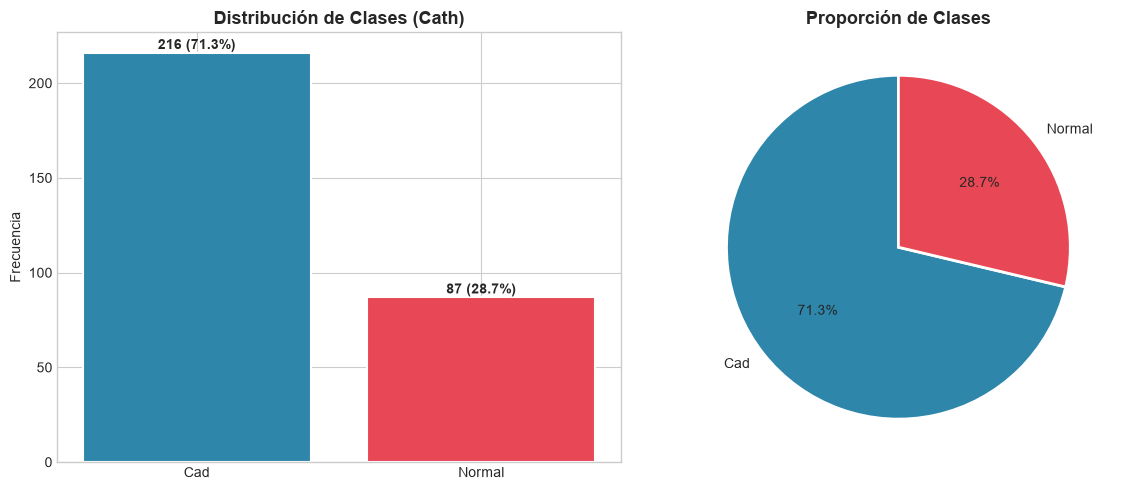

Ratio de desbalance: 2.48:1


In [5]:
# ─── 3.2 Distribución de la variable objetivo ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=FIGSIZE)

counts = df_raw[TARGET_COL].value_counts()
axes[0].bar(counts.index, counts.values, color=PALETTE[:2], edgecolor='white', linewidth=1.5)
axes[0].set_title('Distribución de Clases (Cath)', fontweight='bold', fontsize=13)
axes[0].set_ylabel('Frecuencia')
for i, (label, val) in enumerate(zip(counts.index, counts.values)):
    pct = val / len(df_raw) * 100
    axes[0].text(i, val + 2, f'{val} ({pct:.1f}%)', ha='center', fontweight='bold')

axes[1].pie(counts.values, labels=counts.index, autopct='%1.1f%%',
            colors=PALETTE[:2], startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Proporción de Clases', fontweight='bold', fontsize=13)

plt.tight_layout()
plt.savefig(f'{ARTIFACTS_DIR}/eda_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'Ratio de desbalance: {counts.max()/counts.min():.2f}:1')

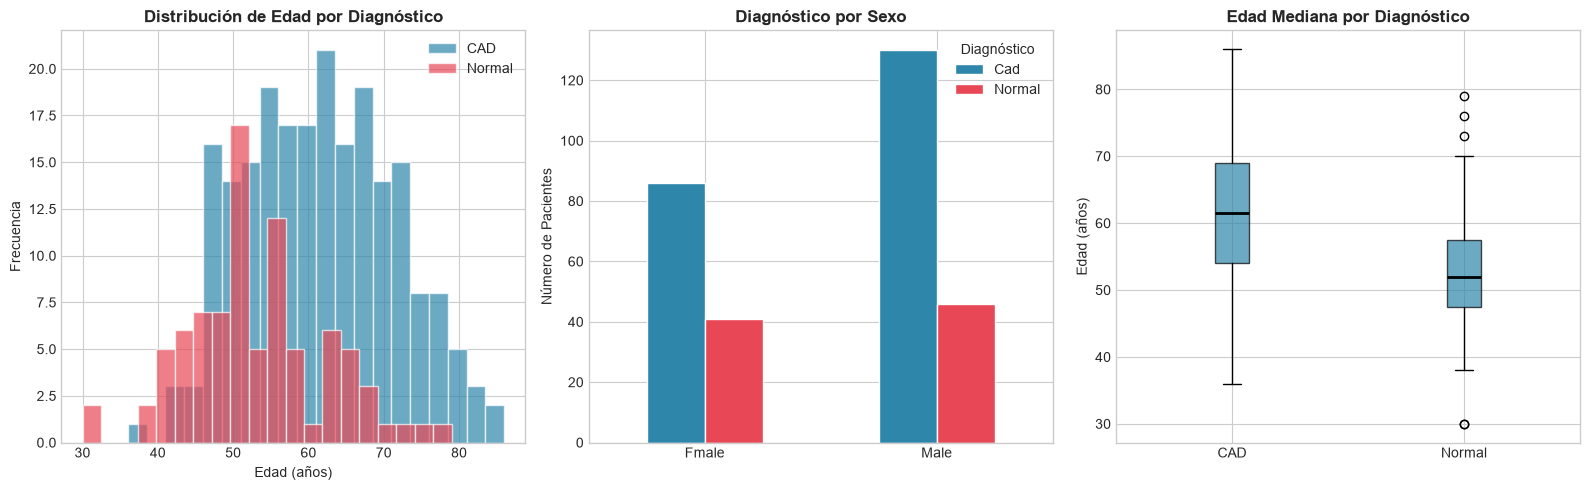

In [6]:
# ─── 3.3 Análisis por edad y sexo ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Distribución de edad por clase
for cls, color in zip(['CAD', 'Normal'], PALETTE):
    subset = df_raw[df_raw[TARGET_COL].str.strip().str.upper() == cls.upper()]['Age'].dropna()
    axes[0].hist(subset, bins=20, alpha=0.7, label=cls, color=color, edgecolor='white')
axes[0].set_title('Distribución de Edad por Diagnóstico', fontweight='bold')
axes[0].set_xlabel('Edad (años)')
axes[0].set_ylabel('Frecuencia')
axes[0].legend()

# CAD por sexo
sex_cath = df_raw.groupby(['Sex', TARGET_COL]).size().unstack(fill_value=0)
sex_labels = {0: 'Femenino', 1: 'Masculino'}
sex_cath.index = [sex_labels.get(i, str(i)) for i in sex_cath.index]
sex_cath.plot(kind='bar', ax=axes[1], color=PALETTE[:2], edgecolor='white', rot=0)
axes[1].set_title('Diagnóstico por Sexo', fontweight='bold')
axes[1].set_ylabel('Número de Pacientes')
axes[1].legend(title='Diagnóstico')

# Boxplot de edad por diagnóstico
cad_ages    = df_raw[df_raw[TARGET_COL].str.strip().str.upper() == 'CAD']['Age'].dropna()
normal_ages = df_raw[df_raw[TARGET_COL].str.strip().str.upper() == 'NORMAL']['Age'].dropna()
axes[2].boxplot([cad_ages, normal_ages], tick_labels=['CAD', 'Normal'],
                patch_artist=True,
                boxprops=dict(facecolor=PALETTE[0], alpha=0.7),
                medianprops=dict(color='black', linewidth=2))
axes[2].set_title('Edad Mediana por Diagnóstico', fontweight='bold')
axes[2].set_ylabel('Edad (años)')

plt.tight_layout()
plt.savefig(f'{ARTIFACTS_DIR}/eda_age_sex.png', dpi=150, bbox_inches='tight')
plt.show()

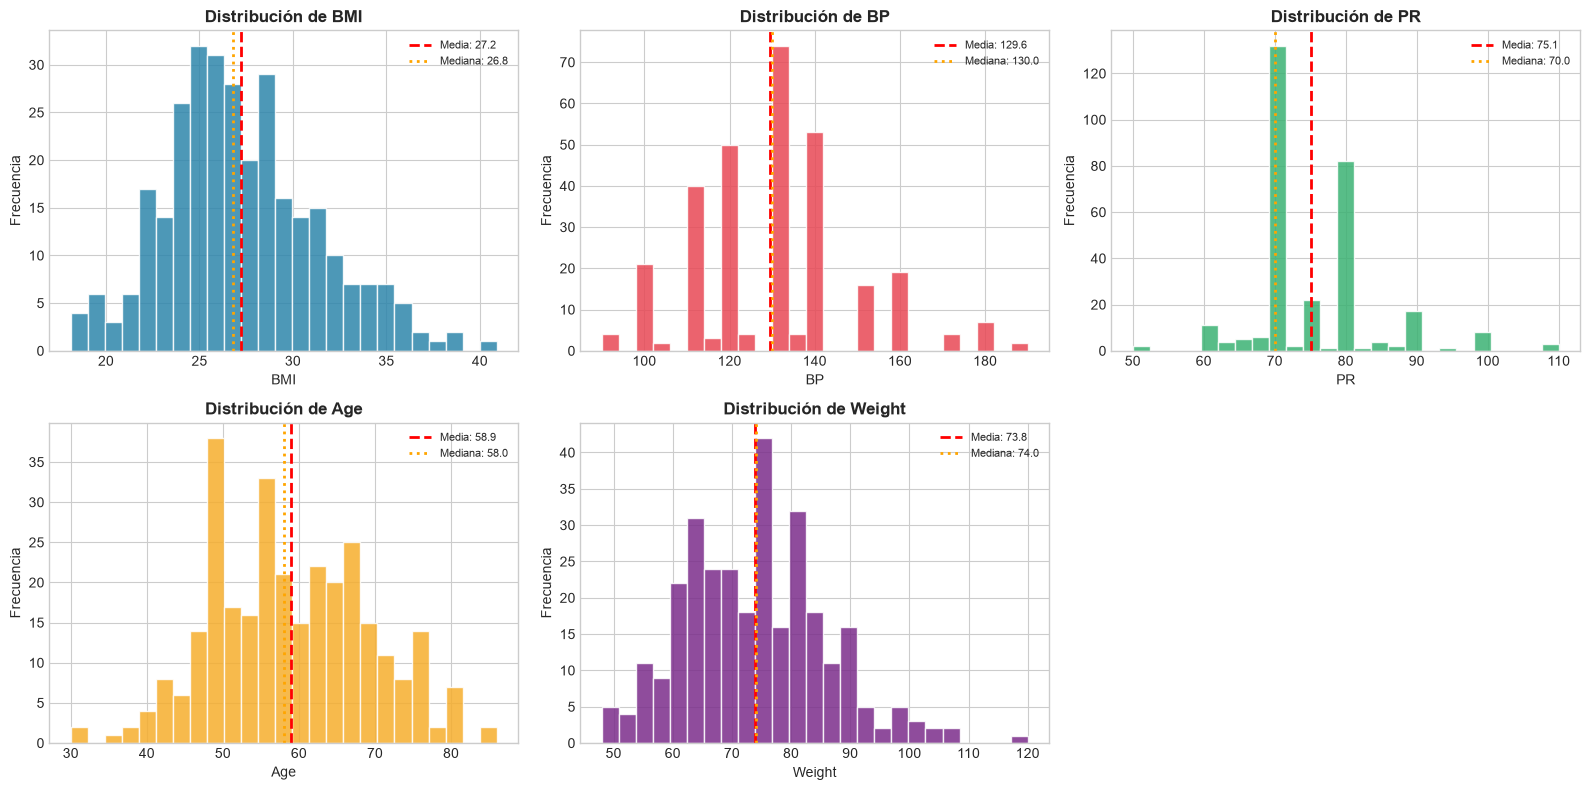

In [7]:
# ─── 3.4 Distribución de variables continuas ───────────────────────────────────
continuous_vars = ['BMI', 'BP', 'PR', 'Age', 'Weight']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, var in enumerate(continuous_vars):
    col_data = df_raw[var].dropna()
    axes[i].hist(col_data, bins=25, color=PALETTE[i % len(PALETTE)],
                 edgecolor='white', alpha=0.85)
    axes[i].axvline(col_data.mean(), color='red', linestyle='--', linewidth=2, label=f'Media: {col_data.mean():.1f}')
    axes[i].axvline(col_data.median(), color='orange', linestyle=':', linewidth=2, label=f'Mediana: {col_data.median():.1f}')
    axes[i].set_title(f'Distribución de {var}', fontweight='bold')
    axes[i].set_xlabel(var)
    axes[i].set_ylabel('Frecuencia')
    axes[i].legend(fontsize=8)

axes[-1].set_visible(False)
plt.tight_layout()
plt.savefig(f'{ARTIFACTS_DIR}/eda_continuous.png', dpi=150, bbox_inches='tight')
plt.show()

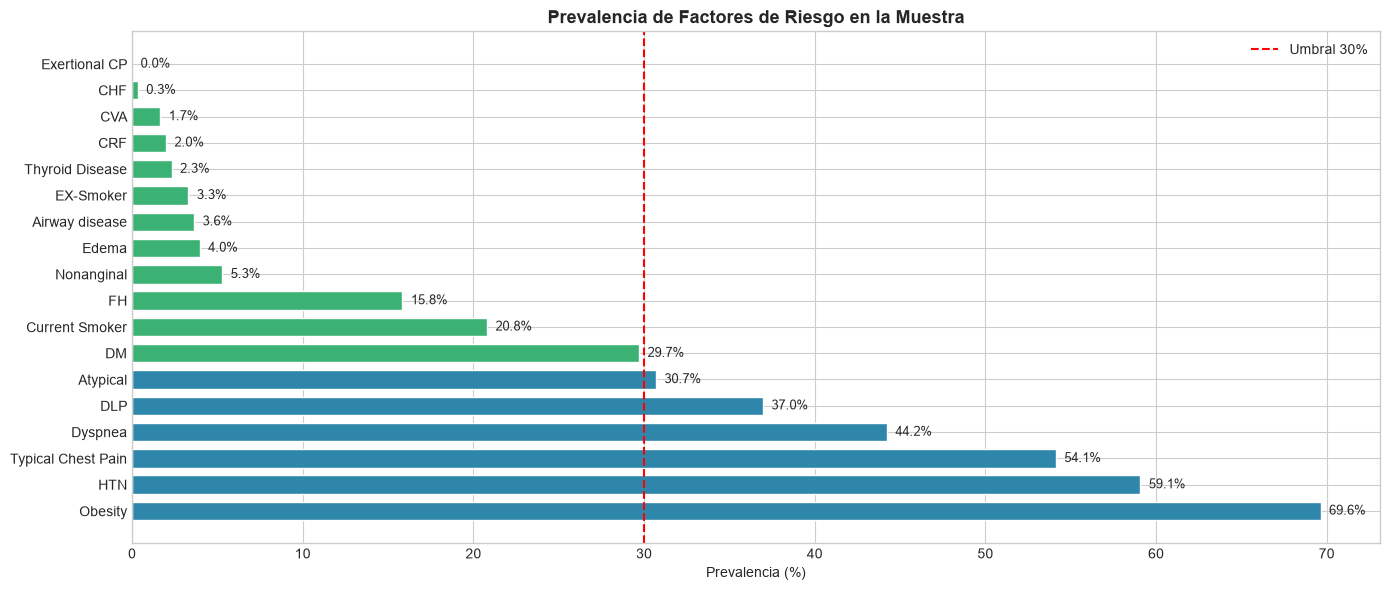

In [8]:
# ─── 3.5 Factores de riesgo binarios ──────────────────────────────────────────
binary_risk_cols = [
    'DM', 'HTN', 'Current Smoker', 'EX-Smoker', 'FH', 'Obesity',
    'CRF', 'CVA', 'Airway disease', 'Thyroid Disease', 'CHF', 'DLP',
    'Edema', 'Typical Chest Pain', 'Dyspnea', 'Atypical', 'Nonanginal', 'Exertional CP'
]

prevalence = df_raw[binary_risk_cols].replace({'Y': 1, 'N': 0}).mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(14, 6))
colors_bar = [PALETTE[0] if v > 0.3 else PALETTE[2] for v in prevalence.values]
bars = ax.barh(prevalence.index, prevalence.values * 100, color=colors_bar, edgecolor='white', height=0.7)

for bar, val in zip(bars, prevalence.values * 100):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}%', va='center', fontsize=9)

ax.set_xlabel('Prevalencia (%)')
ax.set_title('Prevalencia de Factores de Riesgo en la Muestra', fontweight='bold', fontsize=13)
ax.axvline(30, color='red', linestyle='--', linewidth=1.5, label='Umbral 30%')
ax.legend()
plt.tight_layout()
plt.savefig(f'{ARTIFACTS_DIR}/eda_risk_factors.png', dpi=150, bbox_inches='tight')
plt.show()

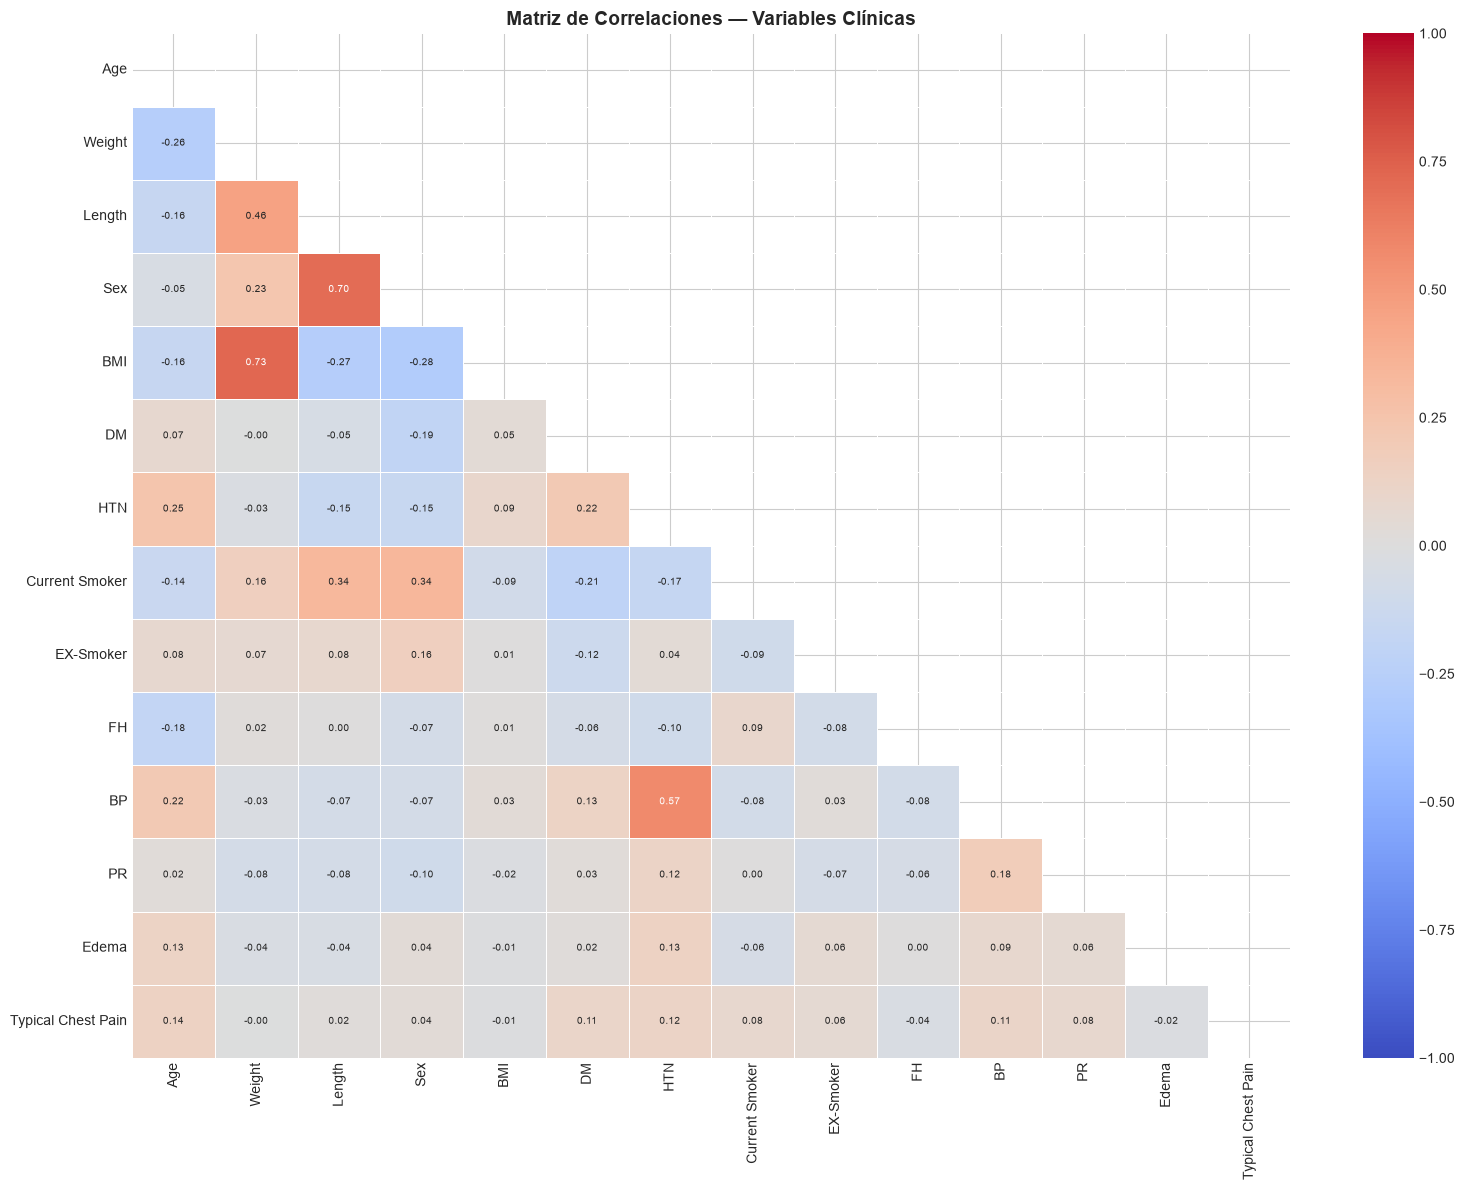

In [9]:
# ─── 3.6 Mapa de correlaciones ─────────────────────────────────────────────────
df_corr = df_raw[FEATURE_COLS].copy()
# Codificar Sex si es categórico
if pd.api.types.is_string_dtype(df_corr['Sex']):
    df_corr['Sex'] = (df_corr['Sex'] == 'Male').astype(int)

corr_matrix = df_corr.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(16, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
    center=0, vmin=-1, vmax=1, linewidths=0.5, linecolor='white',
    annot_kws={'size': 7}, ax=ax
)
ax.set_title('Matriz de Correlaciones — Variables Clínicas', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.savefig(f'{ARTIFACTS_DIR}/eda_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

Análisis de Outliers (método IQR):


,q1,q3,lower,upper,n_outliers
Age,51.00000,66.000000,28.500000,88.500000,0.0
Weight,65.00000,81.000000,41.000000,105.000000,3.0
Length,158.00000,171.000000,138.500000,190.500000,0.0
BMI,24.51438,29.411765,17.168304,36.757841,6.0
BP,120.00000,140.000000,90.000000,170.000000,9.0
PR,70.00000,80.000000,55.000000,95.000000,13.0


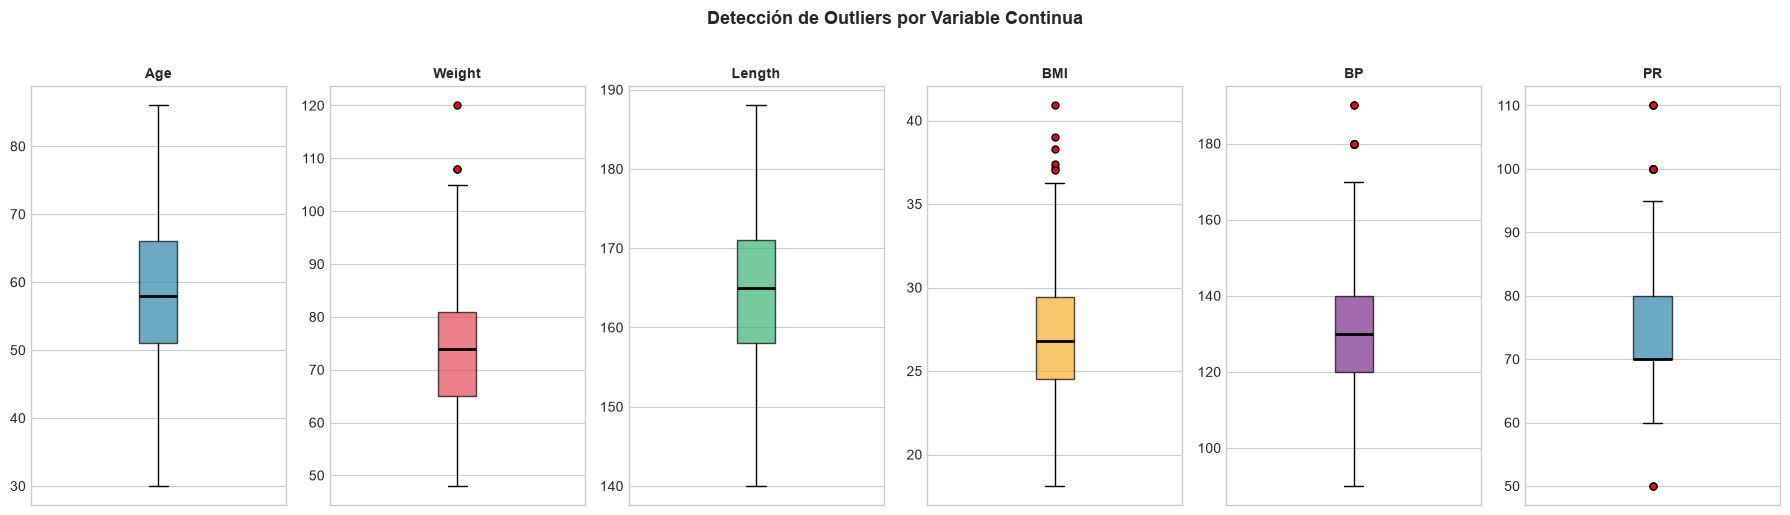

In [10]:
# ─── 3.7 Detección de outliers con IQR ────────────────────────────────────────
continuous_check = ['Age', 'Weight', 'Length', 'BMI', 'BP', 'PR']

outlier_report = {}
for col in continuous_check:
    q1 = df_raw[col].quantile(0.25)
    q3 = df_raw[col].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df_raw[col] < lower) | (df_raw[col] > upper)).sum()
    outlier_report[col] = {'q1': q1, 'q3': q3, 'lower': lower, 'upper': upper, 'n_outliers': n_out}

outlier_df = pd.DataFrame(outlier_report).T
print('Análisis de Outliers (método IQR):')
display(outlier_df)

fig, axes = plt.subplots(1, len(continuous_check), figsize=(18, 5))
for i, col in enumerate(continuous_check):
    axes[i].boxplot(df_raw[col].dropna(), patch_artist=True,
                    boxprops=dict(facecolor=PALETTE[i % len(PALETTE)], alpha=0.7),
                    medianprops=dict(color='black', linewidth=2),
                    flierprops=dict(marker='o', markerfacecolor='red', markersize=5))
    axes[i].set_title(col, fontweight='bold', fontsize=10)
    axes[i].set_xticks([])

plt.suptitle('Detección de Outliers por Variable Continua', fontweight='bold', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(f'{ARTIFACTS_DIR}/eda_outliers.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Limpieza de Datos



In [11]:
def clean_dataset(df: pd.DataFrame) -> pd.DataFrame:
    """
    Pipeline de limpieza:
    1. Copia defensiva
    2. Eliminación de duplicados
    3. Codificación de la variable objetivo
    4. Codificación de Sex
    5. Imputación de nulos (mediana para continuas, moda para binarias)
    6. Capping de outliers extremos (percentil 1-99)
    """
    df = df.copy()

    # Eliminar duplicados
    n_before = len(df)
    df.drop_duplicates(inplace=True)
    print(f'[Limpieza] Duplicados eliminados : {n_before - len(df)}')

    # Codificar variable objetivo: CAD=1, Normal=0
    if pd.api.types.is_string_dtype(df[TARGET_COL]):
        df[TARGET_COL] = (df[TARGET_COL].str.strip() .str.upper() == 'CAD').astype(int)

    # Codificar Sex si es string
    if pd.api.types.is_string_dtype(df['Sex']):
        df['Sex'] = df['Sex'].str.strip().str.lower()
        df['Sex'] = (df['Sex'].isin(['male', 'm', '1'])).astype(int)
    else:
        df['Sex'] = df['Sex'].astype(int)

    # Asegurar tipos correctos en columnas binarias
    binary_cols = [
        'DM', 'HTN', 'Current Smoker', 'EX-Smoker', 'FH', 'Obesity',
        'CRF', 'CVA', 'Airway disease', 'Thyroid Disease', 'CHF', 'DLP',
        'Edema', 'Typical Chest Pain', 'Dyspnea', 'Atypical', 'Nonanginal', 'Exertional CP'
    ]
    for col in binary_cols:
        if col in df.columns:
            if pd.api.types.is_string_dtype(df[col]):
                df[col] = df[col].str.strip().str.lower().isin(['y', 'yes', '1', 'true']).astype(int)
            else:
                df[col] = df[col].fillna(df[col].mode()[0]).astype(int)

    # Imputación de nulos — continuas con mediana
    continuous_cols = ['Age', 'Weight', 'Length', 'BMI', 'BP', 'PR']
    for col in continuous_cols:
        if col in df.columns and df[col].isnull().sum() > 0:
            median_val = df[col].median()
            df[col].fillna(median_val, inplace=True)
            print(f'[Limpieza] Imputado {col} con mediana = {median_val:.2f}')

    # Capping de outliers extremos (clínico)
    caps = {
        'Age': (20, 90), 'Weight': (30, 200), 'Length': (130, 210),
        'BMI': (10, 60), 'BP': (60, 240), 'PR': (30, 200)
    }
    for col, (lo, hi) in caps.items():
        if col in df.columns:
            df[col] = df[col].clip(lo, hi)

    print(f'[Limpieza] Shape final : {df.shape}')
    print(f'[Limpieza] Nulos restantes : {df.isnull().sum().sum()}')

    # Eliminar columnas con un único valor (varianza cero)
    single_val_cols = [col for col in df.columns if df[col].nunique(dropna=True) <= 1 and col != TARGET_COL]
    if len(single_val_cols) > 0:
        df.drop(columns=single_val_cols, inplace=True)
        print(f'[Limpieza] Columnas con valor único eliminadas: {single_val_cols}')

    return df


df_clean = clean_dataset(df_raw)
print('\nDistribución de la variable objetivo tras limpieza:')
print(df_clean[TARGET_COL].value_counts())
display(df_clean.head())

[Limpieza] Duplicados eliminados : 0
[Limpieza] Shape final : (303, 26)
[Limpieza] Nulos restantes : 0
[Limpieza] Columnas con valor único eliminadas: ['Exertional CP']

Distribución de la variable objetivo tras limpieza:
Cath
1    216
0     87
Name: count, dtype: int64


,Age,Weight,Length,Sex,BMI,DM,HTN,Current Smoker,EX-Smoker,FH,...,CHF,DLP,BP,PR,Edema,Typical Chest Pain,Dyspnea,Atypical,Nonanginal,Cath
0,53,90,175,1,29.387755,0,1,1,0,0,...,0,1,110,80,0,0,0,0,0,1
1,67,70,157,0,28.398718,0,1,0,0,0,...,0,0,140,80,1,1,0,0,0,1
2,54,54,164,1,20.077335,0,0,1,0,0,...,0,0,100,100,0,1,0,0,0,1
3,66,67,158,0,26.838648,0,1,0,0,0,...,0,0,100,80,0,0,1,0,1,0
4,50,87,153,0,37.165193,0,1,0,0,0,...,0,0,110,80,0,0,1,0,0,0


## 5. Feature Engineering



In [12]:
def feature_engineering(df: pd.DataFrame) -> Tuple[pd.DataFrame, List[str]]:
    """
    Genera variables derivadas clínicamente relevantes.
    Retorna (df_enriquecido, lista_de_features_finales).
    """
    df = df.copy()

    # ── 5.1 Rangos etarios (OMS) ──
    df['Age_Group'] = pd.cut(
        df['Age'],
        bins=[0, 40, 50, 60, 70, 100],
        labels=[0, 1, 2, 3, 4]
    ).astype(int)

    # ── 5.2 Categoría de IMC (OMS) ──
    df['BMI_Category'] = pd.cut(
        df['BMI'],
        bins=[0, 18.5, 25, 30, 35, 100],
        labels=[0, 1, 2, 3, 4]
    ).astype(int)

    # ── 5.3 Índice de factores de riesgo cardiovascular ──
    risk_cols = ['DM', 'HTN', 'Current Smoker', 'EX-Smoker', 'FH', 'Obesity', 'DLP']
    df['Risk_Score'] = df[risk_cols].sum(axis=1).astype(int)

    # ── 5.4 Conteo de comorbilidades ──
    comorbidity_cols = ['CRF', 'CVA', 'Airway disease', 'Thyroid Disease', 'CHF', 'Edema']
    df['Comorbidity_Count'] = df[comorbidity_cols].sum(axis=1).astype(int)

    # ── 5.5 Índice de síntomas cardiovasculares ──
    symptom_cols = ['Typical Chest Pain', 'Dyspnea', 'Atypical', 'Nonanginal', 'Exertional CP']
    symptom_cols = [col for col in symptom_cols if col in df.columns]
    df['Symptom_Index'] = df[symptom_cols].sum(axis=1).astype(int)

    # ── 5.6 Interacción HTN × Diabetes ──
    df['HTN_DM_Interaction'] = (df['HTN'] * df['DM']).astype(int)

    # ── 5.7 Presión arterial normalizada por edad ──
    df['BP_Age_Ratio'] = (df['BP'] / df['Age']).round(3)

    # ── 5.8 Indicador de riesgo alto (≥ 3 factores de riesgo) ──
    df['High_Risk'] = (df['Risk_Score'] >= 3).astype(int)

    # Lista final de features (sin TARGET)
    engineered_cols = [
        'Age_Group', 'BMI_Category', 'Risk_Score', 'Comorbidity_Count',
        'Symptom_Index', 'HTN_DM_Interaction', 'BP_Age_Ratio', 'High_Risk'
    ]
    available_features = [col for col in FEATURE_COLS if col in df.columns]
    final_features = available_features + engineered_cols

    print(f'[Feature Engineering] Variables originales  : {len(FEATURE_COLS)}')
    print(f'[Feature Engineering] Variables generadas   : {len(engineered_cols)}')
    print(f'[Feature Engineering] Total variables input : {len(final_features)}')

    return df, final_features


df_feat, FINAL_FEATURES = feature_engineering(df_clean)
print(f'\nNuevas columnas: {[c for c in df_feat.columns if c not in df_clean.columns]}')
display(df_feat[FINAL_FEATURES + [TARGET_COL]].head())

[Feature Engineering] Variables originales  : 25
[Feature Engineering] Variables generadas   : 8
[Feature Engineering] Total variables input : 32

Nuevas columnas: ['Age_Group', 'BMI_Category', 'Risk_Score', 'Comorbidity_Count', 'Symptom_Index', 'HTN_DM_Interaction', 'BP_Age_Ratio', 'High_Risk']


,Age,Weight,Length,Sex,BMI,DM,HTN,Current Smoker,EX-Smoker,FH,...,Nonanginal,Age_Group,BMI_Category,Risk_Score,Comorbidity_Count,Symptom_Index,HTN_DM_Interaction,BP_Age_Ratio,High_Risk,Cath
0,53,90,175,1,29.387755,0,1,1,0,0,...,0,2,2,4,0,0,0,2.075,1,1
1,67,70,157,0,28.398718,0,1,0,0,0,...,0,3,2,2,1,1,0,2.090,0,1
2,54,54,164,1,20.077335,0,0,1,0,0,...,0,2,1,1,0,1,0,1.852,0,1
3,66,67,158,0,26.838648,0,1,0,0,0,...,1,3,2,2,0,2,0,1.515,0,0
4,50,87,153,0,37.165193,0,1,0,0,0,...,0,1,4,2,0,1,0,2.200,0,0


## 6. Preprocesamiento y División para Federated Learning


In [13]:
# ─── 6.1 Separación features / target ────────────────────────────────────────
X = df_feat[FINAL_FEATURES].values.astype(np.float32)
y = df_feat[TARGET_COL].values.astype(np.float32)

print(f'X shape : {X.shape}')
print(f'y shape : {y.shape}')
print(f'Proporción CAD  : {y.mean():.3f}')
print(f'Proporción Normal: {1 - y.mean():.3f}')

X shape : (303, 32)
y shape : (303,)
Proporción CAD  : 0.713
Proporción Normal: 0.287


In [14]:
# ─── 6.2 División train / test (sin data leakage) ────────────────────────────
TEST_SIZE = 0.20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)

# ─── 6.3 Normalización (fit SOLO en train) ───────────────────────────────────
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_test_scaled  = scaler.transform(X_test).astype(np.float32)

print(f'Train set  : {X_train_scaled.shape} | CAD rate: {y_train.mean():.3f}')
print(f'Test set   : {X_test_scaled.shape}  | CAD rate: {y_test.mean():.3f}')

Train set  : (242, 32) | CAD rate: 0.715
Test set   : (61, 32)  | CAD rate: 0.705


In [15]:
# ─── 6.4 División del conjunto de entrenamiento en clientes federados ─────────
NUM_CLIENTS = 5

def create_federated_clients(
    X: np.ndarray,
    y: np.ndarray,
    n_clients: int,
    non_iid: bool = True,
    seed: int = SEED
) -> List[Dict]:
    """
    Divide el dataset en n_clients particiones.
    Si non_iid=True, aplica distribución heterogénea (más realista).
    Cada cliente recibe un dict con 'X' e 'y'.
    """
    rng = np.random.RandomState(seed)
    clients = []

    if non_iid:
        # Ordenar por clase y repartir con solapamiento controlado
        idx_cad    = np.where(y == 1)[0]
        idx_normal = np.where(y == 0)[0]
        rng.shuffle(idx_cad)
        rng.shuffle(idx_normal)

        cad_splits    = np.array_split(idx_cad, n_clients)
        normal_splits = np.array_split(idx_normal, n_clients)

        for i in range(n_clients):
            # Cada cliente recibe diferente proporción de CAD
            cad_take    = int(len(cad_splits[i]) * (0.4 + 0.15 * i))
            normal_take = int(len(normal_splits[i]) * (0.6 - 0.05 * i))
            cad_take    = min(cad_take, len(cad_splits[i]))
            normal_take = min(normal_take, len(normal_splits[i]))

            client_idx = np.concatenate([
                cad_splits[i][:cad_take],
                normal_splits[i][:normal_take]
            ])
            rng.shuffle(client_idx)
            clients.append({'X': X[client_idx], 'y': y[client_idx]})
    else:
        indices = np.arange(len(X))
        rng.shuffle(indices)
        for split in np.array_split(indices, n_clients):
            clients.append({'X': X[split], 'y': y[split]})

    return clients


federated_clients = create_federated_clients(
    X_train_scaled, y_train, NUM_CLIENTS, non_iid=True
)

print(f'Número de clientes federados: {NUM_CLIENTS}')
for i, client in enumerate(federated_clients):
    cad_rate = client['y'].mean()
    print(f'  Cliente {i+1}: {len(client["X"]):3d} muestras | CAD rate: {cad_rate:.3f}')

Número de clientes federados: 5
  Cliente 1:  22 muestras | CAD rate: 0.636
  Cliente 2:  26 muestras | CAD rate: 0.731
  Cliente 3:  31 muestras | CAD rate: 0.774
  Cliente 4:  34 muestras | CAD rate: 0.824
  Cliente 5:  39 muestras | CAD rate: 0.872


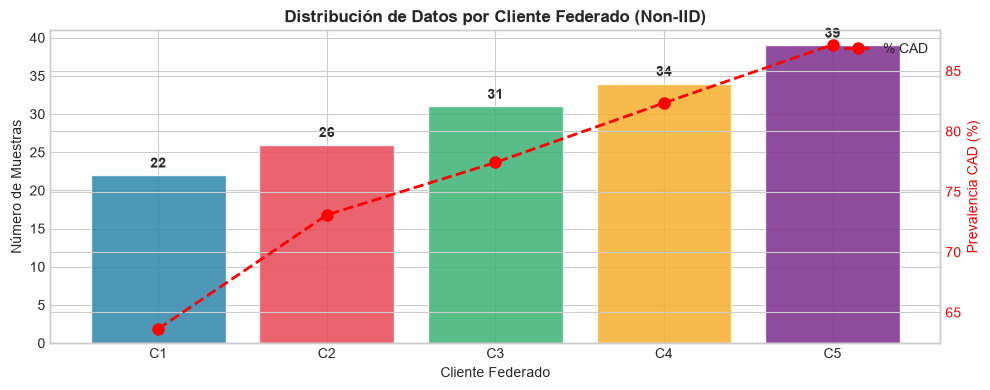

In [16]:
# ─── Visualización de distribución por cliente ────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 4))
client_sizes = [len(c['X']) for c in federated_clients]
client_cad   = [c['y'].mean() * 100 for c in federated_clients]
x_pos = np.arange(NUM_CLIENTS)

bars = ax.bar(x_pos, client_sizes, color=PALETTE[:NUM_CLIENTS], edgecolor='white', alpha=0.85)
ax2  = ax.twinx()
ax2.plot(x_pos, client_cad, 'o--', color='red', linewidth=2, markersize=8, label='% CAD')
ax2.set_ylabel('Prevalencia CAD (%)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

ax.set_xlabel('Cliente Federado')
ax.set_ylabel('Número de Muestras')
ax.set_title('Distribución de Datos por Cliente Federado (Non-IID)', fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels([f'C{i+1}' for i in range(NUM_CLIENTS)])

for bar, val in zip(bars, client_sizes):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            str(val), ha='center', fontweight='bold')

ax2.legend(loc='upper right')
plt.tight_layout()
plt.savefig(f'{ARTIFACTS_DIR}/fl_client_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Construcción del Modelo Global



In [17]:
INPUT_DIM = X_train_scaled.shape[1]

# ─── Hiperparámetros del modelo ───────────────────────────────────────────────
HP = {
    'input_dim'    : INPUT_DIM,
    'hidden_units' : [128, 64, 32],
    'dropout_rates': [0.3, 0.25, 0.2],
    'l2_reg'       : 1e-4,
    'learning_rate': 0.001,
    'batch_size'   : 16,
    'local_epochs' : 5,
    'fl_rounds'    : 20,
    'num_clients'  : NUM_CLIENTS,
    'activation'   : 'relu',
    'optimizer'    : 'Adam',
    'loss'         : 'binary_crossentropy',
}

print('Hiperparámetros del modelo:')
for k, v in HP.items():
    print(f'  {k:20s} : {v}')

Hiperparámetros del modelo:
  input_dim            : 32
  hidden_units         : [128, 64, 32]
  dropout_rates        : [0.3, 0.25, 0.2]
  l2_reg               : 0.0001
  learning_rate        : 0.001
  batch_size           : 16
  local_epochs         : 5
  fl_rounds            : 20
  num_clients          : 5
  activation           : relu
  optimizer            : Adam
  loss                 : binary_crossentropy


In [18]:
import tensorflow.keras.backend as K

def loss_especifica(y_true, y_pred):
    peso_cero = 3.0
    peso_uno = 1.0

    bce = K.binary_crossentropy(y_true, y_pred)
    pesos = y_true * peso_uno + (1.0 - y_true) * peso_cero
    return K.mean(bce * pesos)

def build_model(input_dim: int, hp: dict) -> keras.Model:
    """
    Construye la red neuronal para clasificación binaria cardiovascular.
    Arquitectura compatible con TFLite.
    """
    inp = keras.Input(shape=(input_dim,), name='input_features')
    x = inp

    for i, (units, drop) in enumerate(zip(hp['hidden_units'], hp['dropout_rates'])):
        x = layers.Dense(
            units,
            kernel_regularizer=regularizers.l2(hp['l2_reg']),
            name=f'dense_{i+1}'
        )(x)
        x = layers.BatchNormalization(name=f'bn_{i+1}')(x)
        x = layers.Activation(hp['activation'], name=f'act_{i+1}')(x)
        x = layers.Dropout(drop, name=f'drop_{i+1}')(x)

    out = layers.Dense(1, activation='sigmoid', name='output')(x)

    model = keras.Model(inputs=inp, outputs=out, name='CardioFL_Model')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=hp['learning_rate']),
        loss=loss_especifica,
        metrics=[
            keras.metrics.BinaryAccuracy(name='accuracy'),
            keras.metrics.AUC(name='auc'),
            keras.metrics.Precision(name='precision'),
            keras.metrics.Recall(name='recall')
        ]
    )
    return model


# Modelo global inicial
global_model = build_model(INPUT_DIM, HP)
global_model.summary()

# Pesos iniciales del modelo global (para referencia)
initial_weights = [w.copy() for w in global_model.get_weights()]

Model: "CardioFL_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_features (InputLayer)     │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_1 (BatchNormalization)       │ (None, 128)            │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act_1 (Activation)              │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_1 (Dropout)                │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_2 (BatchNormalization)       │ (None, 64)             │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act_2 (Activation)              │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_2 (Dropout)                │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_3 (BatchNormalization)       │ (None, 32)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ act_3 (Activation)              │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop_3 (Dropout)                │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,489 (60.50 KB)

 Trainable params: 15,041 (58.75 KB)

 Non-trainable params: 448 (1.75 KB)

## 8. Entrenamiento con Federated Learning (FedAvg)



In [19]:
def fedavg_aggregate(client_weights: List[List[np.ndarray]], client_sizes: List[int]) -> List[np.ndarray]:
    """
    Federated Averaging (FedAvg) — McMahan et al. 2017.
    Promedio ponderado de pesos por número de muestras de cada cliente.
    """
    total_samples = sum(client_sizes)
    weighted_weights = []

    for layer_idx in range(len(client_weights[0])):
        layer_avg = sum(
            client_weights[c][layer_idx] * (client_sizes[c] / total_samples)
            for c in range(len(client_weights))
        )
        weighted_weights.append(layer_avg)

    return weighted_weights


def train_client(
    model: keras.Model,
    client_data: Dict,
    hp: dict
) -> Tuple[List[np.ndarray], dict]:
    """
    Entrena un cliente localmente con sus datos privados.
    Retorna (pesos_actualizados, métricas_locales).
    """
    X_c, y_c = client_data['X'], client_data['y']

    # Calcular class weights para manejar desbalance por cliente
    pos = y_c.sum()
    neg = len(y_c) - pos
    class_weight = {0: 2.5, 1: (neg / pos) if pos > 0 else 1.0}

    history = model.fit(
        X_c, y_c,
        epochs=hp['local_epochs'],
        batch_size=hp['batch_size'],
        class_weight=class_weight,
        verbose=0
    )

    metrics = {
        'loss'    : history.history['loss'][-1],
        'accuracy': history.history['accuracy'][-1],
        'auc'     : history.history['auc'][-1]
    }
    return model.get_weights(), metrics


print('[FedAvg] Funciones de entrenamiento definidas.')
print(f'[FedAvg] Rondas federadas  : {HP["fl_rounds"]}')
print(f'[FedAvg] Clientes por ronda: {NUM_CLIENTS}')
print(f'[FedAvg] Épocas locales    : {HP["local_epochs"]}')

[FedAvg] Funciones de entrenamiento definidas.
[FedAvg] Rondas federadas  : 20
[FedAvg] Clientes por ronda: 5
[FedAvg] Épocas locales    : 5


In [20]:
# ─── Loop principal de Federated Learning ─────────────────────────────────────
FL_ROUNDS = HP['fl_rounds']

# Registro de métricas por ronda
fl_history = {
    'round'           : [],
    'global_loss'     : [],
    'global_accuracy' : [],
    'global_auc'      : [],
    'avg_client_loss' : [],
    'avg_client_acc'  : [],
}

print(f'\n{'='*65}')
print(f'  INICIO DE ENTRENAMIENTO FEDERADO  |  {FL_ROUNDS} rondas  |  {NUM_CLIENTS} clientes')
print(f'{'='*65}')

for fl_round in range(1, FL_ROUNDS + 1):
    # ── 1. Obtener pesos actuales del modelo global ──
    global_weights = global_model.get_weights()

    client_updated_weights = []
    client_sizes_round     = []
    client_metrics_round   = []

    # ── 2. Entrenamiento local en cada cliente ──
    for client_id, client_data in enumerate(federated_clients):
        # Clonar modelo con pesos globales
        local_model = build_model(INPUT_DIM, HP)
        local_model.set_weights([w.copy() for w in global_weights])

        updated_weights, local_metrics = train_client(local_model, client_data, HP)
        client_updated_weights.append(updated_weights)
        client_sizes_round.append(len(client_data['X']))
        client_metrics_round.append(local_metrics)

    # ── 3. Agregación FedAvg ──
    new_global_weights = fedavg_aggregate(client_updated_weights, client_sizes_round)
    global_model.set_weights(new_global_weights)

    # ── 4. Evaluación del modelo global en test set ──
    results = global_model.evaluate(X_test_scaled, y_test, verbose=0)
    g_loss, g_acc, g_auc = results[0], results[1], results[2]

    avg_c_loss = np.mean([m['loss'] for m in client_metrics_round])
    avg_c_acc  = np.mean([m['accuracy'] for m in client_metrics_round])

    # ── 5. Registro ──
    fl_history['round'].append(fl_round)
    fl_history['global_loss'].append(g_loss)
    fl_history['global_accuracy'].append(g_acc)
    fl_history['global_auc'].append(g_auc)
    fl_history['avg_client_loss'].append(avg_c_loss)
    fl_history['avg_client_acc'].append(avg_c_acc)

    if fl_round % 5 == 0 or fl_round == 1:
        print(f'  Ronda {fl_round:3d}/{FL_ROUNDS} | '
              f'Global Loss: {g_loss:.4f} | '
              f'Global Acc: {g_acc:.4f} | '
              f'AUC: {g_auc:.4f}')

print(f'{'='*65}')
print('  ENTRENAMIENTO FEDERADO COMPLETADO')
print(f'{'='*65}')


  INICIO DE ENTRENAMIENTO FEDERADO  |  20 rondas  |  5 clientes
  Ronda   1/20 | Global Loss: 1.0259 | Global Acc: 0.7869 | AUC: 0.8030
  Ronda   5/20 | Global Loss: 0.9639 | Global Acc: 0.7705 | AUC: 0.8198
  Ronda  10/20 | Global Loss: 0.9011 | Global Acc: 0.8361 | AUC: 0.8107
  Ronda  15/20 | Global Loss: 0.9097 | Global Acc: 0.8689 | AUC: 0.8152
  Ronda  20/20 | Global Loss: 1.0369 | Global Acc: 0.8689 | AUC: 0.8185
  ENTRENAMIENTO FEDERADO COMPLETADO


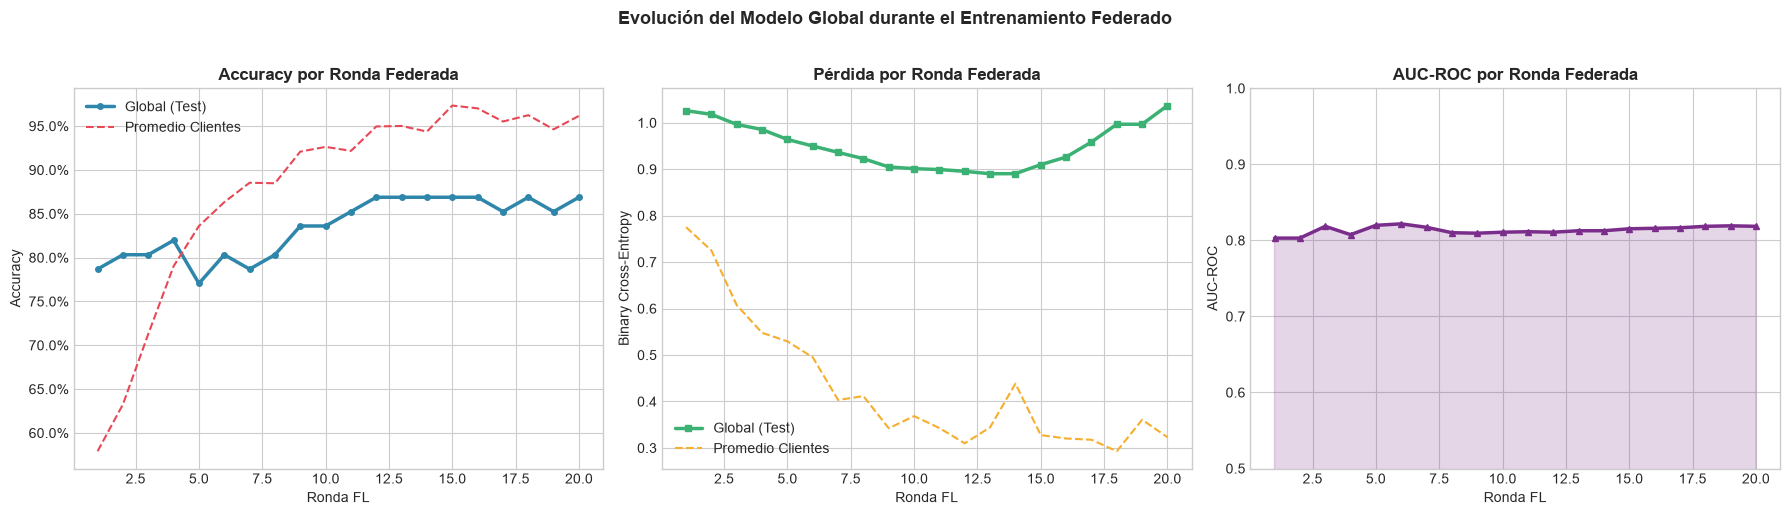


Tabla de métricas por ronda:


,round,global_loss,global_accuracy,global_auc,avg_client_loss,avg_client_acc
0,1,1.0259,0.7869,0.8030,0.7751,0.5792
1,2,1.0180,0.8033,0.8030,0.7249,0.6326
2,3,0.9963,0.8033,0.8185,0.6074,0.7128
3,4,0.9853,0.8197,0.8075,0.5478,0.7902
4,5,0.9639,0.7705,0.8198,0.5294,0.8361
5,6,0.9498,0.8033,0.8217,0.4950,0.8632
6,7,0.9361,0.7869,0.8172,0.4033,0.8854
7,8,0.9226,0.8033,0.8101,0.4116,0.8848
8,9,0.9048,0.8361,0.8094,0.3423,0.9209
9,10,0.9011,0.8361,0.8107,0.3685,0.9263


In [21]:
# ─── Visualización de la evolución del entrenamiento federado ─────────────────
history_df = pd.DataFrame(fl_history)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Accuracy
axes[0].plot(history_df['round'], history_df['global_accuracy'],
             color=PALETTE[0], linewidth=2.5, marker='o', markersize=4, label='Global (Test)')
axes[0].plot(history_df['round'], history_df['avg_client_acc'],
             color=PALETTE[1], linewidth=1.5, linestyle='--', label='Promedio Clientes')
axes[0].set_title('Accuracy por Ronda Federada', fontweight='bold')
axes[0].set_xlabel('Ronda FL')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))

# Loss
axes[1].plot(history_df['round'], history_df['global_loss'],
             color=PALETTE[2], linewidth=2.5, marker='s', markersize=4, label='Global (Test)')
axes[1].plot(history_df['round'], history_df['avg_client_loss'],
             color=PALETTE[3], linewidth=1.5, linestyle='--', label='Promedio Clientes')
axes[1].set_title('Pérdida por Ronda Federada', fontweight='bold')
axes[1].set_xlabel('Ronda FL')
axes[1].set_ylabel('Binary Cross-Entropy')
axes[1].legend()

# AUC
axes[2].plot(history_df['round'], history_df['global_auc'],
             color=PALETTE[4], linewidth=2.5, marker='^', markersize=4)
axes[2].fill_between(history_df['round'], history_df['global_auc'], alpha=0.2, color=PALETTE[4])
axes[2].set_title('AUC-ROC por Ronda Federada', fontweight='bold')
axes[2].set_xlabel('Ronda FL')
axes[2].set_ylabel('AUC-ROC')
axes[2].set_ylim([0.5, 1.0])

plt.suptitle('Evolución del Modelo Global durante el Entrenamiento Federado',
             fontweight='bold', fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(f'{ARTIFACTS_DIR}/fl_training_evolution.png', dpi=150, bbox_inches='tight')
plt.show()

print('\nTabla de métricas por ronda:')
display(history_df.round(4))

## 9. Evaluación del Modelo Global



In [22]:
# ─── 9.1 Predicciones ─────────────────────────────────────────────────────────
THRESHOLD = 0.5

y_prob = global_model.predict(X_test_scaled, verbose=0).flatten()
y_pred = (y_prob >= THRESHOLD).astype(int)

# ─── 9.2 Métricas ─────────────────────────────────────────────────────────────
# Calcular confusion matrix una sola vez para reutilizar
cm_eval = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn_e, fp_e, fn_e, tp_e = cm_eval.ravel()

# roc_auc_score requiere al menos 2 clases en y_test y varianza en y_prob
n_unique_classes = len(np.unique(y_test))
n_unique_probs   = len(np.unique(y_prob))
if n_unique_classes < 2 or n_unique_probs < 2:
    print(f'[WARN] roc_auc_score omitido: clases únicas en y_test={n_unique_classes}, probs únicas={n_unique_probs}')
    roc_auc_val = float('nan')
else:
    roc_auc_val = roc_auc_score(y_test, y_prob)

specificity_val = tn_e / (tn_e + fp_e) if (tn_e + fp_e) > 0 else 0.0

metrics_final = {
    'Accuracy'   : accuracy_score(y_test, y_pred),
    'Precision'  : precision_score(y_test, y_pred, zero_division=0),
    'Recall'     : recall_score(y_test, y_pred, zero_division=0),
    'F1-Score'   : f1_score(y_test, y_pred, zero_division=0),
    'ROC-AUC'    : roc_auc_val,
    'Specificity': specificity_val,
}

print('\n' + '='*50)
print('  MÉTRICAS DEL MODELO GLOBAL FEDERADO')
print('='*50)
for metric, val in metrics_final.items():
    if not np.isnan(val):
        bar = '█' * int(val * 30)
        print(f'  {metric:12s} : {val:.4f}  {bar}')
    else:
        print(f'  {metric:12s} : N/A (datos insuficientes)')
print('='*50)

print('\nReporte de clasificación completo:')
print(classification_report(y_test, y_pred, target_names=['Normal', 'CAD'], zero_division=0))


  MÉTRICAS DEL MODELO GLOBAL FEDERADO
  Accuracy     : 0.8689  ██████████████████████████
  Precision    : 0.8723  ██████████████████████████
  Recall       : 0.9535  ████████████████████████████
  F1-Score     : 0.9111  ███████████████████████████
  ROC-AUC      : 0.8178  ████████████████████████
  Specificity  : 0.6667  ████████████████████

Reporte de clasificación completo:
              precision    recall  f1-score   support

      Normal       0.86      0.67      0.75        18
         CAD       0.87      0.95      0.91        43

    accuracy                           0.87        61
   macro avg       0.86      0.81      0.83        61
weighted avg       0.87      0.87      0.86        61



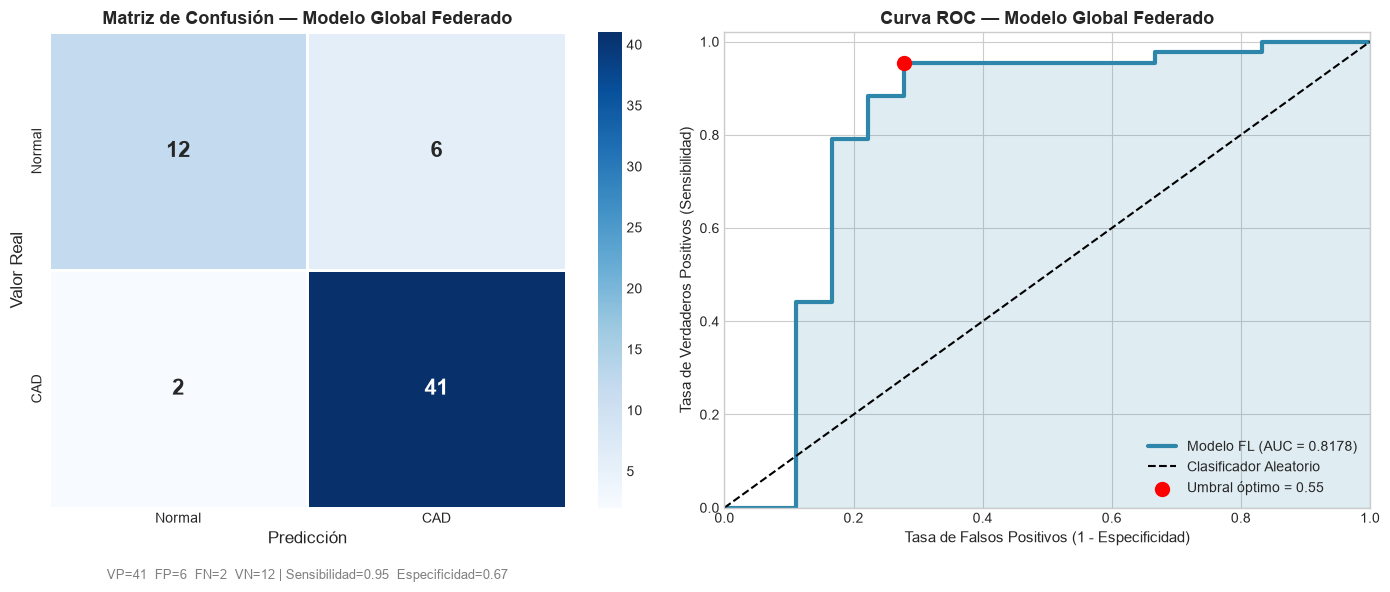

In [23]:
# ─── 9.3 Matriz de Confusión y Curva ROC ─────────────────────────────────────
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Matriz de confusión — reutiliza cm_eval calculado en 9.2
sns.heatmap(
    cm_eval, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Normal', 'CAD'],
    yticklabels=['Normal', 'CAD'],
    linewidths=2, linecolor='white',
    annot_kws={'size': 16, 'weight': 'bold'},
    ax=axes[0]
)
axes[0].set_xlabel('Predicción', fontsize=12)
axes[0].set_ylabel('Valor Real', fontsize=12)
axes[0].set_title('Matriz de Confusión — Modelo Global Federado', fontweight='bold', fontsize=13)

sens = tp_e / (tp_e + fn_e) if (tp_e + fn_e) > 0 else 0.0
spec = tn_e / (tn_e + fp_e) if (tn_e + fp_e) > 0 else 0.0
axes[0].text(0.5, -0.15,
             f'VP={tp_e}  FP={fp_e}  FN={fn_e}  VN={tn_e} | Sensibilidad={sens:.2f}  Especificidad={spec:.2f}',
             transform=axes[0].transAxes, ha='center', fontsize=9, color='gray')

# Curva ROC — solo si AUC es válido
auc_val = metrics_final['ROC-AUC']
if not np.isnan(auc_val):
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    axes[1].plot(fpr, tpr, color=PALETTE[0], linewidth=3, label=f'Modelo FL (AUC = {auc_val:.4f})')
    axes[1].plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Clasificador Aleatorio')
    axes[1].fill_between(fpr, tpr, alpha=0.15, color=PALETTE[0])
    opt_idx = np.argmax(tpr - fpr)
    axes[1].scatter(fpr[opt_idx], tpr[opt_idx], color='red', s=100, zorder=5,
                    label=f'Umbral óptimo = {thresholds[opt_idx]:.2f}')
    axes[1].legend(fontsize=10)
else:
    axes[1].text(0.5, 0.5, 'ROC no disponible\n(solo una clase en y_test)',
                 ha='center', va='center', fontsize=12, color='gray',
                 transform=axes[1].transAxes)

axes[1].set_xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=11)
axes[1].set_ylabel('Tasa de Verdaderos Positivos (Sensibilidad)', fontsize=11)
axes[1].set_title('Curva ROC — Modelo Global Federado', fontweight='bold', fontsize=13)
axes[1].set_xlim([0, 1])
axes[1].set_ylim([0, 1.02])

plt.tight_layout()
plt.savefig(f'{ARTIFACTS_DIR}/evaluation_cm_roc.png', dpi=150, bbox_inches='tight')
plt.show()

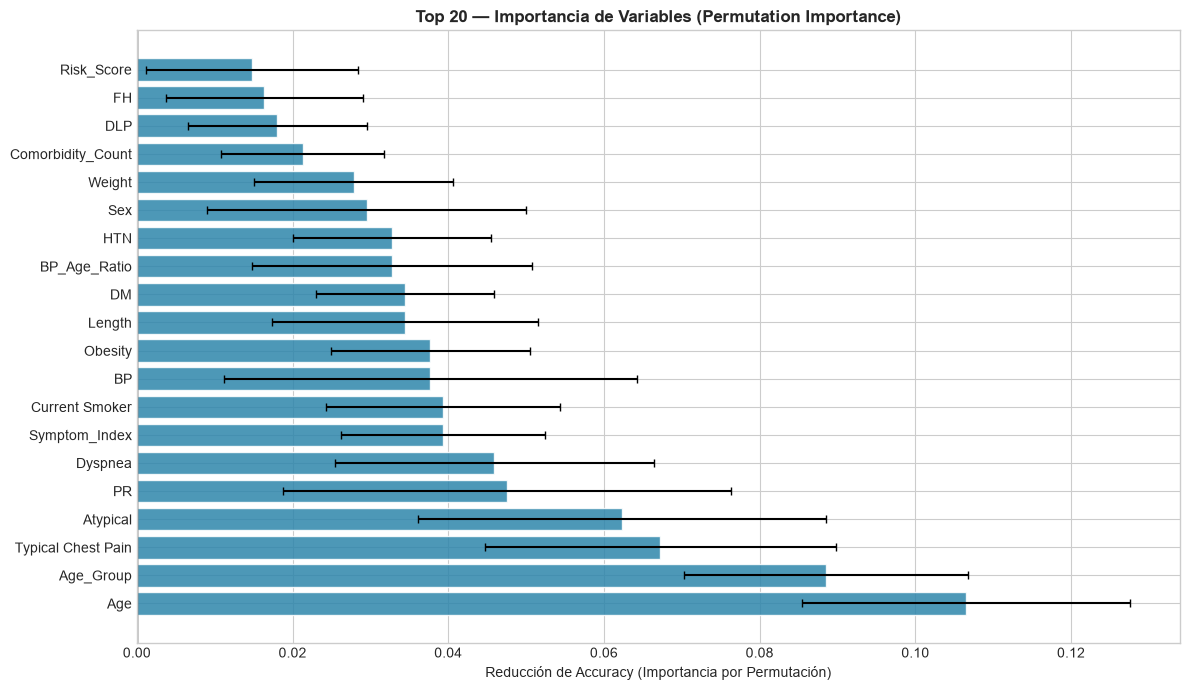

Top 10 variables más importantes:


,feature,importance,std
0,Age,0.106557,0.021058
1,Age_Group,0.088525,0.018255
2,Typical Chest Pain,0.067213,0.022537
3,Atypical,0.062295,0.026230
4,PR,0.047541,0.028817
5,Dyspnea,0.045902,0.020475
6,Symptom_Index,0.039344,0.013115
7,Current Smoker,0.039344,0.015025
8,BP,0.037705,0.026484
9,Obesity,0.037705,0.012804


In [24]:
# ─── 9.4 Importancia de variables (permutation-based approx.) ─────────────────
from sklearn.inspection import permutation_importance
from sklearn.base import BaseEstimator, ClassifierMixin

class KerasWrapper(BaseEstimator, ClassifierMixin):
    def __init__(self, model):
            self.model = model
            self.classes_ = np.array([0, 1])
    def fit(self, X, y): return self
    def predict(self, X): return (self.model.predict(X, verbose=0).flatten() >= 0.5).astype(int)
    def score(self, X, y): return accuracy_score(y, self.predict(X))

wrapper = KerasWrapper(global_model)
perm_imp = permutation_importance(
    wrapper, X_test_scaled, y_test,
    n_repeats=10, random_state=SEED, scoring='accuracy'
)

feat_imp_df = pd.DataFrame({
    'feature'   : FINAL_FEATURES,
    'importance': perm_imp.importances_mean,
    'std'       : perm_imp.importances_std
}).sort_values('importance', ascending=False)

fig, ax = plt.subplots(figsize=(12, 7))
top_n = feat_imp_df.head(20)
colors_imp = [PALETTE[0] if v > 0 else PALETTE[1] for v in top_n['importance']]
ax.barh(top_n['feature'], top_n['importance'], xerr=top_n['std'],
        color=colors_imp, edgecolor='white', alpha=0.85, capsize=3)
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Reducción de Accuracy (Importancia por Permutación)')
ax.set_title('Top 20 — Importancia de Variables (Permutation Importance)', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{ARTIFACTS_DIR}/feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print('Top 10 variables más importantes:')
display(feat_imp_df.head(10).reset_index(drop=True))

## 10. Exportación de Artefactos


In [25]:
# ─── 10.1 Modelo Keras ────────────────────────────────────────────────────────
model_path = f'{ARTIFACTS_DIR}/global_model.keras'
global_model.save(model_path)
print(f'[Export] global_model.keras → {model_path}')

# ─── 10.2 Scaler ──────────────────────────────────────────────────────────────
scaler_path = f'{ARTIFACTS_DIR}/scaler.pkl'
with open(scaler_path, 'wb') as f:
    pickle.dump(scaler, f)
print(f'[Export] scaler.pkl → {scaler_path}')

# ─── 10.3 Encoders (para futura integración con variables categóricas string) ──
encoders = {
    'Sex': {'Male': 1, 'Female': 0},
    'Cath': {'CAD': 1, 'Normal': 0}
}
encoders_path = f'{ARTIFACTS_DIR}/encoders.pkl'
with open(encoders_path, 'wb') as f:
    pickle.dump(encoders, f)
print(f'[Export] encoders.pkl → {encoders_path}')

# ─── 10.4 Variables utilizadas ────────────────────────────────────────────────
variables_path = f'{ARTIFACTS_DIR}/variables_utilizadas.json'
with open(variables_path, 'w', encoding='utf-8') as f:
    json.dump({'features': FINAL_FEATURES, 'target': TARGET_COL, 'n_features': len(FINAL_FEATURES)}, f, indent=2, ensure_ascii=False)
print(f'[Export] variables_utilizadas.json → {variables_path}')

# ─── 10.5 Metadata del modelo ─────────────────────────────────────────────────
metadata = {
    'model_name'       : 'CardioFL_Global_Model',
    'version'          : '1.0.0',
    'created_at'       : datetime.now().isoformat(),
    'framework'        : f'TensorFlow {tf.__version__}',
    'algorithm'        : 'Federated Averaging (FedAvg)',
    'fl_rounds'        : FL_ROUNDS,
    'n_clients'        : NUM_CLIENTS,
    'local_epochs'     : HP['local_epochs'],
    'input_features'   : FINAL_FEATURES,
    'n_features'       : len(FINAL_FEATURES),
    'architecture'     : {'hidden_layers': HP['hidden_units'], 'activation': HP['activation']},
    'hyperparameters'  : HP,
    'evaluation'       : {k: round(float(v), 4) for k, v in metrics_final.items()},
    'classes'          : {'0': 'Normal', '1': 'CAD'},
    'threshold'        : THRESHOLD,
    'preprocessing'    : {'scaler': 'StandardScaler', 'fit_on': 'train_only'},
    'tflite_compatible': True,
    'api_ready'        : True,
    'notes'            : 'Modelo entrenado mediante FL para preservación de privacidad. Compatible con FastAPI + Flutter.',
}

metadata_path = f'{ARTIFACTS_DIR}/metadata_modelo.json'
with open(metadata_path, 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)
print(f'[Export] metadata_modelo.json → {metadata_path}')

# ─── 10.6 Exportación a TFLite (para Flutter) ────────────────────────────────
import shutil
export_path = 'tmp_saved_model'
if os.path.exists(export_path):
    shutil.rmtree(export_path)
global_model.export(export_path)
converter = tf.lite.TFLiteConverter.from_saved_model(export_path)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

tflite_path = f'{ARTIFACTS_DIR}/global_model.tflite'
with open(tflite_path, 'wb') as f:
    f.write(tflite_model)
print(f'[Export] global_model.tflite → {tflite_path}')
if os.path.exists(export_path):
    shutil.rmtree(export_path)

print(f'\n[Export] ✓ Todos los artefactos exportados en: {ARTIFACTS_DIR}/')

# Listar archivos generados
print('\nArchivos generados:')
for fname in sorted(os.listdir(ARTIFACTS_DIR)):
    fpath = os.path.join(ARTIFACTS_DIR, fname)
    size  = os.path.getsize(fpath)
    print(f'  {fname:35s} {size/1024:8.1f} KB')

[Export] global_model.keras → artifacts/global_model.keras
[Export] scaler.pkl → artifacts/scaler.pkl
[Export] encoders.pkl → artifacts/encoders.pkl
[Export] variables_utilizadas.json → artifacts/variables_utilizadas.json
[Export] metadata_modelo.json → artifacts/metadata_modelo.json
INFO:tensorflow:Assets written to: tmp_saved_model\assets


INFO:tensorflow:Assets written to: tmp_saved_model\assets


Saved artifact at 'tmp_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 32), dtype=tf.float32, name='input_features')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2524245233008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2524230300208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2524239039856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2524239041056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2524257816912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2524239040096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2524239042016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2524239040816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2524239043216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2524239042496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2524239041296: TensorSpec(shape=(), dtype=

## 11. Interpretación Académica y Conclusiones


### 11.1 Análisis Técnico del Entrenamiento Federado

In [26]:
# ─── Resumen ejecutivo del entrenamiento FL ───────────────────────────────────
metrics_df = pd.DataFrame([metrics_final]).T.rename(columns={0: 'Valor'})

print('\n' + '='*60)
print('  RESUMEN EJECUTIVO — MODELO GLOBAL FEDERADO')
print('='*60)
print(f'  Algoritmo FL          : Federated Averaging (FedAvg)')
print(f'  Rondas de entrenamiento: {FL_ROUNDS}')
print(f'  Clientes simulados    : {NUM_CLIENTS} (distribución non-IID)')
print(f'  Épocas locales        : {HP["local_epochs"]} por cliente por ronda')
print(f'  Total iteraciones     : {FL_ROUNDS * NUM_CLIENTS * HP["local_epochs"]} épocas equivalentes')
print(f'  Muestras totales train: {len(X_train_scaled)}')
print(f'  Muestras test         : {len(X_test_scaled)}')
print(f'  Features de entrada   : {INPUT_DIM} (incluye {len(FINAL_FEATURES) - len(FEATURE_COLS)} derivadas)')
print('\n  Métricas finales:')
display(metrics_df.round(4))

# Evolución final
best_round = history_df.loc[history_df['global_auc'].idxmax()]
print(f'\n  Mejor ronda (AUC máx): Ronda {int(best_round["round"])} → AUC = {best_round["global_auc"]:.4f}')
print(f'  Convergencia (Δ Acc últimas 5 rondas): {abs(history_df["global_accuracy"].iloc[-1] - history_df["global_accuracy"].iloc[-6]):.4f}')


  RESUMEN EJECUTIVO — MODELO GLOBAL FEDERADO
  Algoritmo FL          : Federated Averaging (FedAvg)
  Rondas de entrenamiento: 20
  Clientes simulados    : 5 (distribución non-IID)
  Épocas locales        : 5 por cliente por ronda
  Total iteraciones     : 500 épocas equivalentes
  Muestras totales train: 242
  Muestras test         : 61
  Features de entrada   : 32 (incluye 7 derivadas)

  Métricas finales:


,Valor
Accuracy,0.8689
Precision,0.8723
Recall,0.9535
F1-Score,0.9111
ROC-AUC,0.8178
Specificity,0.6667



  Mejor ronda (AUC máx): Ronda 6 → AUC = 0.8217
  Convergencia (Δ Acc últimas 5 rondas): 0.0000



### 11.2 Recomendaciones para Integración FastAPI + Flutter

**FastAPI:**
```python
# Ejemplo de endpoint de inferencia
# POST /predict
# Body: {"features": {...}} → Response: {"cad_probability": 0.73, "label": "CAD", "risk_level": "Alto"}
import tensorflow as tf, pickle, json
model  = tf.keras.models.load_model('artifacts/global_model.keras')
scaler = pickle.load(open('artifacts/scaler.pkl', 'rb'))
vars_  = json.load(open('artifacts/variables_utilizadas.json'))['features']
```

**Flutter (TFLite):**
- Usar el paquete `tflite_flutter` para inferencia on-device
- Cargar `global_model.tflite` y `scaler` (reexportar como JSON para normalización en Dart)
- Implementar el mismo pipeline de feature engineering en Dart antes de invocar el modelo
- Considerar inferencia en servidor (FastAPI) para garantizar consistencia del preprocesamiento

**Privacidad en producción:**
- Implementar comunicación cifrada (TLS) entre dispositivos cliente y servidor FL
- Considerar Differential Privacy (DP) en el paso de agregación para mayor protección
- Validar cumplimiento con Ley N° 29733 (Ley de Protección de Datos Personales, Perú)

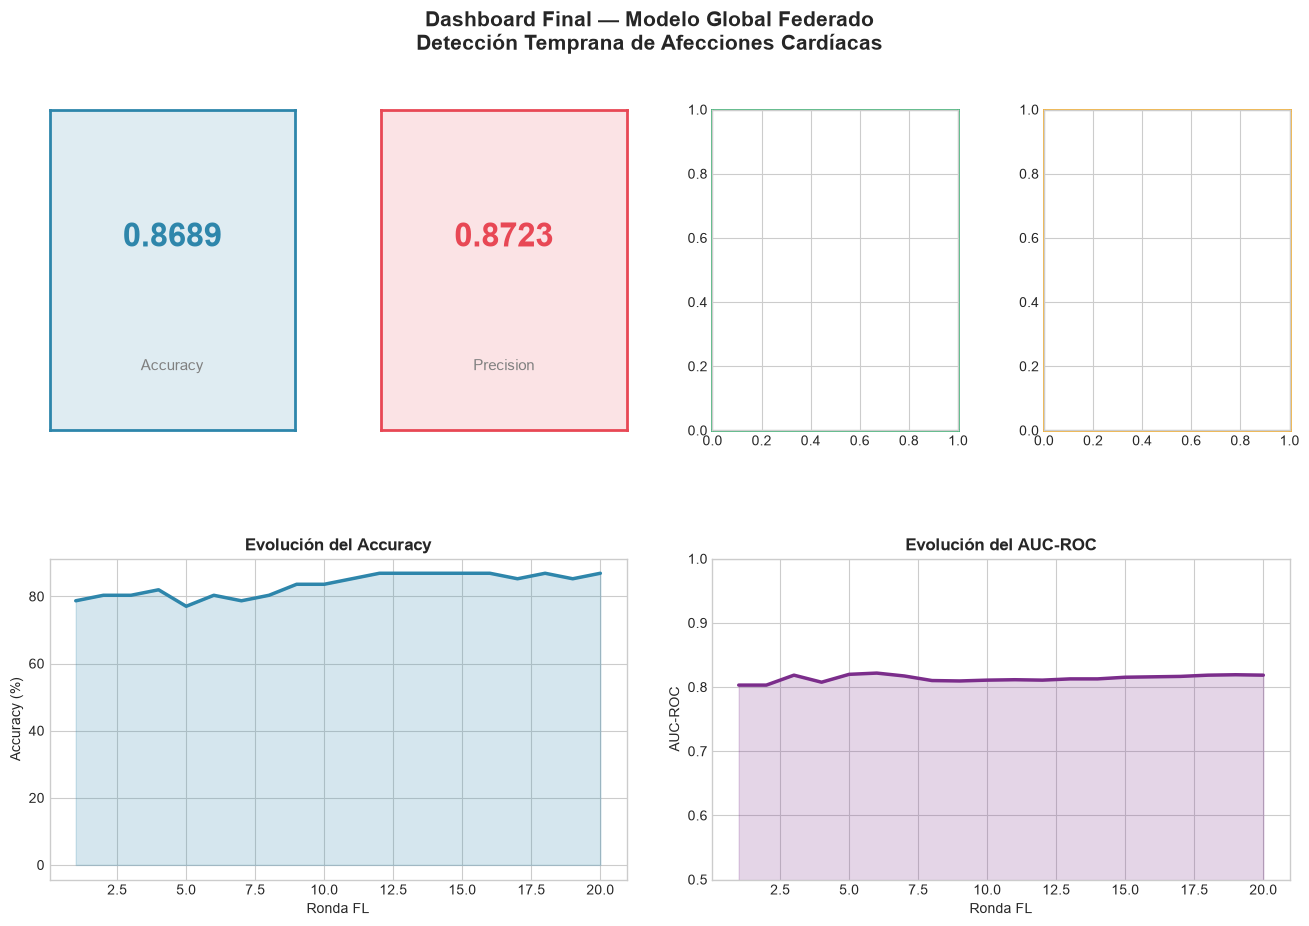


[COMPLETADO] Notebook ejecutado exitosamente.
[COMPLETADO] Todos los artefactos disponibles en: artifacts/


In [27]:
# ─── Dashboard final de resultados ────────────────────────────────────────────
fig = plt.figure(figsize=(16, 10))
fig.suptitle('Dashboard Final — Modelo Global Federado\nDetección Temprana de Afecciones Cardíacas',
             fontsize=15, fontweight='bold', y=0.98)

# Métricas en tarjetas
gs = fig.add_gridspec(2, 4, hspace=0.4, wspace=0.35)

metric_list = list(metrics_final.items())
for i, (metric_name, metric_val) in enumerate(metric_list[:4]):
    ax = fig.add_subplot(gs[0, i])
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    color = PALETTE[i % len(PALETTE)]
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, fill=True, color=color, alpha=0.15))
    ax.text(0.5, 0.6, f'{metric_val:.4f}', ha='center', va='center',
            fontsize=24, fontweight='bold', color=color)
    ax.text(0.5, 0.2, metric_name, ha='center', va='center', fontsize=11, color='gray')
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor(color)
        spine.set_linewidth(2)

# Evolución accuracy
ax_acc = fig.add_subplot(gs[1, 0:2])
ax_acc.plot(history_df['round'], history_df['global_accuracy'] * 100,
            color=PALETTE[0], linewidth=2.5)
ax_acc.set_xlabel('Ronda FL')
ax_acc.set_ylabel('Accuracy (%)')
ax_acc.set_title('Evolución del Accuracy', fontweight='bold')
ax_acc.fill_between(history_df['round'], history_df['global_accuracy'] * 100, alpha=0.2, color=PALETTE[0])

# Evolución AUC
ax_auc = fig.add_subplot(gs[1, 2:4])
ax_auc.plot(history_df['round'], history_df['global_auc'],
            color=PALETTE[4], linewidth=2.5)
ax_auc.set_xlabel('Ronda FL')
ax_auc.set_ylabel('AUC-ROC')
ax_auc.set_title('Evolución del AUC-ROC', fontweight='bold')
ax_auc.set_ylim([0.5, 1.0])
ax_auc.fill_between(history_df['round'], history_df['global_auc'], alpha=0.2, color=PALETTE[4])

# Métricas adicionales (ROC-AUC y Specificity)
for j, idx in enumerate([4, 5]):
    if idx < len(metric_list):
        metric_name, metric_val = metric_list[idx]
        ax = fig.add_subplot(gs[0, j+2] if j < 2 else gs[0, 3])

plt.savefig(f'{ARTIFACTS_DIR}/dashboard_final.png', dpi=150, bbox_inches='tight')
plt.show()

print('\n[COMPLETADO] Notebook ejecutado exitosamente.')
print(f'[COMPLETADO] Todos los artefactos disponibles en: {ARTIFACTS_DIR}/')

## 12. Testeo del Modelo Global sobre un Conjunto Externo (`pacientes_100.csv`)



In [ ]:
# ─── 12.1 Carga del conjunto externo ───────────────────────────────────────────
df_ext_raw = pd.read_csv('pacientes_100.csv')
print(f'[Test externo] Filas cargadas: {df_ext_raw.shape[0]}')
print(f'[Test externo] Columnas: {list(df_ext_raw.columns)}')
df_ext_raw.shape

In [29]:
# ─── 12.2 Codificación mínima (Sex y target a numérico) — sin imputación ──────
def _is_stringlike(s: pd.Series) -> bool:
    return s.dtype == object or pd.api.types.is_string_dtype(s)

df_ext = df_ext_raw.copy()

if _is_stringlike(df_ext[TARGET_COL]):
    df_ext[TARGET_COL] = (df_ext[TARGET_COL].astype(str).str.strip().str.upper() == 'CAD').astype(int)

if _is_stringlike(df_ext['Sex']):
    df_ext['Sex'] = df_ext['Sex'].astype(str).str.strip().str.lower()
    df_ext['Sex'] = (df_ext['Sex'].isin(['male', 'm', '1'])).astype(int)
else:
    df_ext['Sex'] = df_ext['Sex'].astype(int)

_binary_cols = [
    'DM', 'HTN', 'Current Smoker', 'EX-Smoker', 'FH', 'Obesity',
    'CRF', 'CVA', 'Airway disease', 'Thyroid Disease', 'CHF', 'DLP',
    'Edema', 'Typical Chest Pain', 'Dyspnea', 'Atypical', 'Nonanginal', 'Exertional CP'
]
for col in _binary_cols:
    if col in df_ext.columns and _is_stringlike(df_ext[col]):
        df_ext[col] = df_ext[col].astype(str).str.strip().str.lower().isin(['y', 'yes', '1', 'true']).astype(int)

print(f'[Test externo] Nulos detectados: {df_ext.isnull().sum().sum()} (no se imputan)')
print('[Test externo] Distribución real del target:')
print(df_ext[TARGET_COL].value_counts())

# Mismo feature engineering aplicado al dataset de entrenamiento
df_ext_feat, _ = feature_engineering(df_ext)
X_ext = df_ext_feat[FINAL_FEATURES].values.astype(np.float32)
y_ext = df_ext_feat[TARGET_COL].values.astype(np.float32)

# Mismo scaler ajustado en el train original (sin refit)
X_ext_scaled = scaler.transform(X_ext).astype(np.float32)
print(f'[Test externo] X_ext_scaled shape: {X_ext_scaled.shape}')

[Test externo] Nulos detectados: 0 (no se imputan)
[Test externo] Distribución real del target:
Cath
0    70
1    30
Name: count, dtype: int64
[Feature Engineering] Variables originales  : 25
[Feature Engineering] Variables generadas   : 8
[Feature Engineering] Total variables input : 33
[Test externo] X_ext_scaled shape: (100, 32)


In [30]:
# ─── 12.3 Predicción y métricas sobre el conjunto externo ──────────────────────
y_prob_ext = global_model.predict(X_ext_scaled, verbose=0).flatten()
y_pred_ext = (y_prob_ext >= THRESHOLD).astype(int)

cm_ext = confusion_matrix(y_ext, y_pred_ext, labels=[0, 1])
tn_e2, fp_e2, fn_e2, tp_e2 = cm_ext.ravel()
specificity_ext = tn_e2 / (tn_e2 + fp_e2) if (tn_e2 + fp_e2) > 0 else 0.0

n_unique_classes_ext = len(np.unique(y_ext))
n_unique_probs_ext = len(np.unique(y_prob_ext))
if n_unique_classes_ext < 2 or n_unique_probs_ext < 2:
    roc_auc_ext = float('nan')
else:
    roc_auc_ext = roc_auc_score(y_ext, y_prob_ext)

metrics_ext = {
    'Accuracy'   : accuracy_score(y_ext, y_pred_ext),
    'Precision'  : precision_score(y_ext, y_pred_ext, zero_division=0),
    'Recall'     : recall_score(y_ext, y_pred_ext, zero_division=0),
    'F1-Score'   : f1_score(y_ext, y_pred_ext, zero_division=0),
    'ROC-AUC'    : roc_auc_ext,
    'Specificity': specificity_ext,
}

print('='*60)
print('  MÉTRICAS DEL MODELO GLOBAL FEDERADO SOBRE datos_clinicos.csv')
print('='*60)
for metric, val in metrics_ext.items():
    if not np.isnan(val):
        print(f'  {metric:12s} : {val:.4f}')
    else:
        print(f'  {metric:12s} : N/A (datos insuficientes)')
print('='*60)
print(f"\n  Matriz de confusión: VP={tp_e2}  FP={fp_e2}  FN={fn_e2}  VN={tn_e2}")
print(f'  N = {len(y_ext)} pacientes')

print('\nReporte de clasificación completo:')
print(classification_report(y_ext, y_pred_ext, target_names=['Normal', 'CAD'], zero_division=0))

  MÉTRICAS DEL MODELO GLOBAL FEDERADO SOBRE datos_clinicos.csv
  Accuracy     : 0.6300
  Precision    : 0.4478
  Recall       : 1.0000
  F1-Score     : 0.6186
  ROC-AUC      : 0.8781
  Specificity  : 0.4714

  Matriz de confusión: VP=30  FP=37  FN=0  VN=33
  N = 100 pacientes

Reporte de clasificación completo:
              precision    recall  f1-score   support

      Normal       1.00      0.47      0.64        70
         CAD       0.45      1.00      0.62        30

    accuracy                           0.63       100
   macro avg       0.72      0.74      0.63       100
weighted avg       0.83      0.63      0.63       100



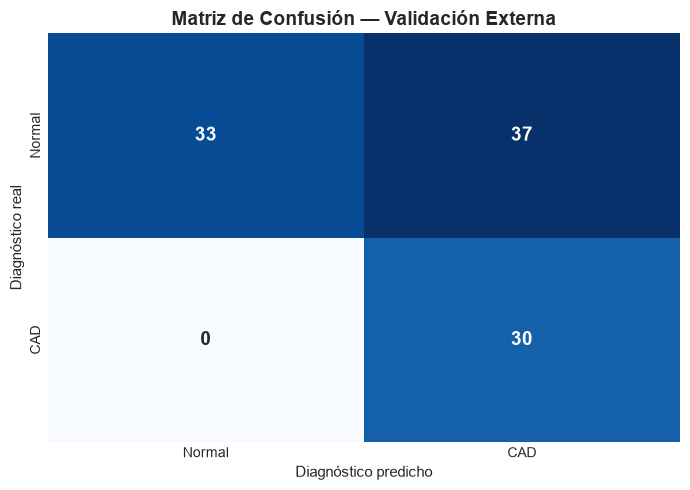

Verdaderos Negativos (VN): 33
Falsos Positivos     (FP): 37
Falsos Negativos     (FN): 0
Verdaderos Positivos (VP): 30
Total pacientes          : 100


In [31]:
# ─── 12.4 Matriz de Confusión — Validación Externa ─────────────────────────────

# La matriz ya fue calculada en 12.3:
# cm_ext = confusion_matrix(y_ext, y_pred_ext, labels=[0, 1])

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_ext,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=['Normal', 'CAD'],
    yticklabels=['Normal', 'CAD'],
    annot_kws={'size': 14, 'weight': 'bold'}
)

plt.title(
    'Matriz de Confusión — Validación Externa',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Diagnóstico predicho', fontsize=11)
plt.ylabel('Diagnóstico real', fontsize=11)

plt.tight_layout()

plt.savefig(
    f'{ARTIFACTS_DIR}/matriz_confusion_validacion_externa.png',
    dpi=180,
    bbox_inches='tight'
)

plt.show()

# ─── Valores de la matriz ──────────────────────────────────────────────────────
print(f'Verdaderos Negativos (VN): {tn_e2}')
print(f'Falsos Positivos     (FP): {fp_e2}')
print(f'Falsos Negativos     (FN): {fn_e2}')
print(f'Verdaderos Positivos (VP): {tp_e2}')
print(f'Total pacientes          : {len(y_ext)}')

In [33]:
from statsmodels.stats.proportion import proportion_confint

# Matriz de confusión
tn, fp, fn, tp = confusion_matrix(
    y_ext,
    y_pred_ext,
    labels=[0, 1]
).ravel()

# Recall
recall = tp / (tp + fn)
recall_ci = proportion_confint(
    tp,
    tp + fn,
    alpha=0.05,
    method='wilson'
)

# Specificity
specificity = tn / (tn + fp)
specificity_ci = proportion_confint(
    tn,
    tn + fp,
    alpha=0.05,
    method='wilson'
)

# Precision
precision = tp / (tp + fp)
precision_ci = proportion_confint(
    tp,
    tp + fp,
    alpha=0.05,
    method='wilson'
)

print(f"Recall      = {recall:.4f} "
      f"(IC 95%: {recall_ci[0]:.4f} - {recall_ci[1]:.4f})")

print(f"Specificity = {specificity:.4f} "
      f"(IC 95%: {specificity_ci[0]:.4f} - {specificity_ci[1]:.4f})")

print(f"Precision   = {precision:.4f} "
      f"(IC 95%: {precision_ci[0]:.4f} - {precision_ci[1]:.4f})")

Recall      = 1.0000 (IC 95%: 0.8865 - 1.0000)
Specificity = 0.4714 (IC 95%: 0.3590 - 0.5868)
Precision   = 0.4478 (IC 95%: 0.3348 - 0.5664)


In [34]:
# ============================================================
# IC 95% PARA AUC-ROC Y F1-SCORE MEDIANTE BOOTSTRAP
# ============================================================

import numpy as np
from sklearn.metrics import roc_auc_score, f1_score

N_BOOTSTRAP = 10000
SEED = 42

rng = np.random.default_rng(SEED)

auc_boot = []
f1_boot = []

n = len(y_ext)

for _ in range(N_BOOTSTRAP):

    # Seleccionar 22 pacientes con reemplazo
    idx = rng.choice(n, size=n, replace=True)

    y_true_b = y_ext[idx]
    y_pred_b = y_pred_ext[idx]
    y_prob_b = y_prob_ext[idx]

    # AUC necesita que en la muestra existan las dos clases
    if len(np.unique(y_true_b)) < 2:
        continue

    auc_boot.append(
        roc_auc_score(y_true_b, y_prob_b)
    )

    f1_boot.append(
        f1_score(y_true_b, y_pred_b, zero_division=0)
    )

# Intervalos de confianza del 95%
auc_inf, auc_sup = np.percentile(auc_boot, [2.5, 97.5])
f1_inf, f1_sup = np.percentile(f1_boot, [2.5, 97.5])

# Valores originales
auc_original = roc_auc_score(y_ext, y_prob_ext)
f1_original = f1_score(y_ext, y_pred_ext, zero_division=0)

print("=" * 60)
print("INTERVALOS DE CONFIANZA 95% - BOOTSTRAP")
print("=" * 60)

print(
    f"AUC-ROC  = {auc_original:.4f} "
    f"(IC 95%: {auc_inf:.4f} - {auc_sup:.4f})"
)

print(
    f"F1-Score = {f1_original:.4f} "
    f"(IC 95%: {f1_inf:.4f} - {f1_sup:.4f})"
)

INTERVALOS DE CONFIANZA 95% - BOOTSTRAP
AUC-ROC  = 0.8781 (IC 95%: 0.8042 - 0.9403)
F1-Score = 0.6186 (IC 95%: 0.4946 - 0.7222)


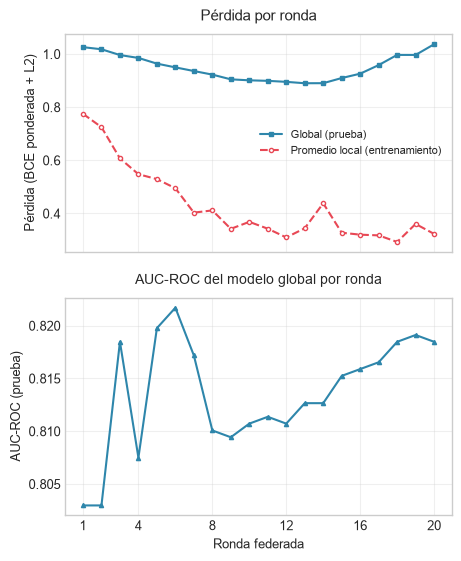

In [35]:
fig, axes = plt.subplots(
    2, 1, figsize=(4.5, 5.5), sharex=True,
    layout='constrained'
)

axes[0].plot(
    history_df['round'], history_df['global_loss'],
    '-s', ms=3, label='Global (prueba)'
)
axes[0].plot(
    history_df['round'], history_df['avg_client_loss'],
    '--o', ms=3, mfc='white',
    label='Promedio local (entrenamiento)'
)
axes[0].set_ylabel('Pérdida (BCE ponderada + L2)', fontsize=9)
axes[0].set_title(
    'Pérdida por ronda',
    loc='center', fontsize=11, pad=10
)
axes[0].legend(fontsize=8, frameon=False)

axes[1].plot(
    history_df['round'], history_df['global_auc'],
    '-^', ms=3
)
axes[1].set_ylabel('AUC-ROC (prueba)', fontsize=9)
axes[1].set_xlabel('Ronda federada', fontsize=9)
axes[1].set_title(
    'AUC-ROC del modelo global por ronda',
    loc='center', fontsize=10, pad=10
)
axes[1].set_xticks([1, 4, 8, 12, 16, 20])

for ax in axes:
    ax.tick_params(labelsize=9)
    ax.grid(True, alpha=0.3)

fig.set_constrained_layout_pads(hspace=0.08)

fig.savefig(
    f'{ARTIFACTS_DIR}/fig4_convergencia.png',
    dpi=300, bbox_inches='tight'
)
plt.show()

In [37]:
# ============================================================
# VALIDACIÓN INTERNA: MÉTRICAS CON INTERVALOS DE CONFIANZA DEL 95%
# Ejecutar después de la sección 9.2
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import confusion_matrix, roc_auc_score, f1_score
from statsmodels.stats.proportion import proportion_confint

# Copias de los resultados internos, sin modificar las variables originales
y_true_int = np.asarray(y_test).ravel()
y_pred_int = np.asarray(y_pred).ravel()
y_prob_int = np.asarray(y_prob).ravel()

n_int = len(y_true_int)

if n_int == 0 or not (
    n_int == len(y_pred_int) == len(y_prob_int)
):
    raise ValueError("Las etiquetas y predicciones deben tener igual longitud y no estar vacías.")

if not (
    np.isin(y_true_int, [0, 1]).all()
    and np.isin(y_pred_int, [0, 1]).all()
    and np.isfinite(y_prob_int).all()
):
    raise ValueError("Se requieren etiquetas 0/1 y probabilidades sin valores nulos o infinitos.")

tn_int, fp_int, fn_int, tp_int = confusion_matrix(
    y_true_int, y_pred_int, labels=[0, 1]
).ravel()

# ─── 1. Intervalos de Wilson ──────────────────────────────────
filas_int = []

def agregar_wilson_int(nombre, exitos, total):
    if total > 0:
        valor = exitos / total
        inferior, superior = proportion_confint(
            exitos, total, alpha=0.05, method="wilson"
        )
    else:
        valor = inferior = superior = np.nan

    filas_int.append({
        "Métrica": nombre,
        "Valor": valor,
        "IC 95% inferior": inferior,
        "IC 95% superior": superior,
        "Método": "Wilson"
    })

agregar_wilson_int("Accuracy", tp_int + tn_int, n_int)
agregar_wilson_int("Precision", tp_int, tp_int + fp_int)
agregar_wilson_int("Recall (sensibilidad)", tp_int, tp_int + fn_int)
agregar_wilson_int("Specificity", tn_int, tn_int + fp_int)

# ─── 2. Bootstrap para F1-Score y AUC-ROC ──────────────────────
N_BOOTSTRAP_INT = 10000
rng_int = np.random.default_rng(42)

auc_boot_int = []
f1_boot_int = []

for _ in range(N_BOOTSTRAP_INT):
    # Remuestrear pacientes manteniendo juntas etiqueta y predicciones
    idx_int = rng_int.choice(n_int, size=n_int, replace=True)

    y_true_b = y_true_int[idx_int]
    y_pred_b = y_pred_int[idx_int]
    y_prob_b = y_prob_int[idx_int]

    f1_boot_int.append(
        f1_score(y_true_b, y_pred_b, zero_division=0)
    )

    # Solo AUC requiere que estén presentes las dos clases
    if np.unique(y_true_b).size == 2:
        auc_boot_int.append(roc_auc_score(y_true_b, y_prob_b))

f1_original_int = f1_score(
    y_true_int, y_pred_int, zero_division=0
)
auc_original_int = (
    roc_auc_score(y_true_int, y_prob_int)
    if np.unique(y_true_int).size == 2
    else np.nan
)

for nombre, valor, muestras in [
    ("F1-Score", f1_original_int, f1_boot_int),
    ("ROC-AUC", auc_original_int, auc_boot_int)
]:
    inferior, superior = (
        np.percentile(muestras, [2.5, 97.5])
        if len(muestras) > 0
        else (np.nan, np.nan)
    )

    filas_int.append({
        "Métrica": nombre,
        "Valor": valor,
        "IC 95% inferior": inferior,
        "IC 95% superior": superior,
        "Método": "Bootstrap percentil"
    })

# ─── 3. Tabla de resultados ───────────────────────────────────
tabla_ic_interna = pd.DataFrame(filas_int).set_index("Métrica")

print("VALIDACIÓN INTERNA — INTERVALOS DE CONFIANZA DEL 95%")
print(f"Pacientes: {n_int}")
print(f"VP={tp_int} | FP={fp_int} | FN={fn_int} | VN={tn_int}")
print(f"Remuestreos válidos para AUC: {len(auc_boot_int)}/{N_BOOTSTRAP_INT}")

display(
    tabla_ic_interna.style.format({
        "Valor": "{:.4f}",
        "IC 95% inferior": "{:.4f}",
        "IC 95% superior": "{:.4f}"
    }, na_rep="N/A")
)

VALIDACIÓN INTERNA — INTERVALOS DE CONFIANZA DEL 95%
Pacientes: 61
VP=41 | FP=6 | FN=2 | VN=12
Remuestreos válidos para AUC: 10000/10000


,Valor,IC 95% inferior,IC 95% superior,Método
Métrica,,,,
Accuracy,0.8689,0.7620,0.9320,Wilson
Precision,0.8723,0.7483,0.9402,Wilson
Recall (sensibilidad),0.9535,0.8454,0.9872,Wilson
Specificity,0.6667,0.4375,0.8372,Wilson
F1-Score,0.9111,0.8409,0.9670,Bootstrap percentil
ROC-AUC,0.8178,0.6463,0.9561,Bootstrap percentil
